**<h1><center>Week 1 — Statistical Estimation in Practice</center></h1>**
<center>Course: Machine Learning For Signal Processing</center>
<center>Amirkabir University of Technology (Tehran Polytechnic) - Department of Electrical Engineering
</center>

---
Complementory notebook for module 1, week 1.   
Presented by: **Amirsadra Khodadadi**  

*If you have any questions, please contact the TAs.* 
___

# Set Up

## Instructions

###  Requirements

This notebook uses Python and the following libraries:
- **NumPy** — Numerical computation and simulation.
- **Matplotlib** — Data visualization.
- **SciPy** — Probability distributions and statistical calculations.

you can install the required libraries using:
```bash
python -m pip install --upgrade numpy matplotlib scipy
```
If you are working directly in Jupyter Notebook, you can also install the libraries using:
```python
%pip install --upgrade numpy matplotlib scipy
```
**Note:** NumPy version 2.0 or newer is required because the notebook uses `np.trapezoid()`.


### Plotting Style

The notebook uses a custom color palette and an optional hand-drawn plotting style.
The hand-drawn appearance is enabled using:
```python
plt.xkcd()
```
If you prefer standard Matplotlib plots, you can **comment out** the following lines in the initial setup cells:
```python
import logging
```
and:
```python
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.xkcd()
```

**Note:** The logging configuration suppresses warnings about missing XKCD fonts. It does not affect the numerical calculations.  
After changing the plotting style, restart the kernel and rerun the notebook to ensure that the new settings are applied.

### Reproducibility

The experiments use fixed random seeds to generate reproducible results.
You can change these seeds to generate different noise realizations and investigate how the estimated parameters change.
The numerical values may differ after modifying simulation parameters or random seeds, but the theoretical relationships should remain valid under the stated model assumptions.


### Optional Investigations

Some experiments include sections labeled **Optional**.

These sections provide additional explanations, simulations, and opportunities for independent exploration.
They are not required for following the main TA session, although you are encouraged to modify simulation parameters, rerun the experiments, and compare their observations with the theoretical predictions.

## Imports and Modules

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

import logging       # simply for xkcd plots, can be commented out.

C:\Users\USER\AppData\Local\Temp\ipykernel_31180\766825649.py:3: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.1)
  from scipy.stats import norm


## Plot Settings

In [2]:
# Color palette 
TEAL = "#0B5963"
RED = "#F08080"
GRAY = "#8D969C"
LIGHT_GRAY = "#D9DFE2"
YELLOW = "#E9BD42"
DARK = "#263238"

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": DARK,
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "text.color": DARK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

# simply for xkcd plots, can be commented out.
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR) 
plt.xkcd()  

# Part I: From Noisy Observations to Statistical Estimation

## Experiment 1: Maximum Likelihood Estimation

### Estimating the Amplitude of a Known Signal

This experiment investigates how an unknown signal amplitude can be estimated from noisy observations using Maximum Likelihood Estimation (MLE). A simple example is given to understand the relationship between observations, likelihood, and parameter estimation.

Imagine a measurement system that produces a characteristic signal whenever a particular event occurs.

The shape of this signal is known from calibration or previous measurements, but its amplitude may vary.

For example:

- **Biomedical engineering:** Estimating the amplitude of a known evoked-response waveform.
- **Telecommunications:** Estimating the amplitude of a received reference signal.
- **Control systems:** Estimating the magnitude of a known system response.
- **Electronics:** Measuring the amplitude of a transient pulse.
- **Radar:** Estimating the strength of a received echo.

In all these examples, we know the expected signal shape but must estimate its amplitude from noisy measurements.

#### Observation Model

Suppose we observe the signal y:
$$
y[n] = a\,s[n] + w[n]
$$
where:
<br>
* $s[n]$ is a known waveform.
* $a$ is the unknown amplitude that we want to estimate.
* $w[n]$ is additive white Gaussian noise.
* $y[n]$ is the observed signal.

We assume that the noise samples are independent and identically distributed: 
$$
w[n] \overset{\mathrm{i.i.d.}}{\sim} \mathcal{N}(0,\sigma^2)
$$
The goal is to estimate $a$ from the observed signal $y[n]$.
<br>
For this experiment, we will use a Gaussian-shaped pulse as our known waveform:
$$
s(t) = \exp\left(-\frac{t^2}{2b^2}\right)
$$
where $b$ controls the pulse width. 

We normalize the pulse so that:

$$
\max_n s[n]=1
$$

and the clean signal is therefore:

$$
x[n]=a\,s[n]
$$

and our measurement is:

$$
y[n]=x[n]+w[n]
$$

We assume that the pulse shape is known, while its amplitude is unknown to the estimator.

> ***Q1**: If we observe the same signal twice, with different noise realizations, should we obtain exactly the same amplitude estimate?*

#### Parameters

In [3]:
rng = np.random.default_rng(42)

N = 121
a_true = 1.5
sigma_true = 0.48
pulse_width = 0.55

t = np.linspace(-3.5, 3.5, N)  #time axis

s = np.exp(-0.5 * (t / pulse_width)**2) #known gaussian pulse


s = s / np.max(s) #normalization

peak_idx = np.argmax(s)

x = a_true * s #final signal

#### Signal Definition

In [4]:
w1 = rng.normal(0, sigma_true, N)
w2 = rng.normal(0, sigma_true, N)

y1 = x + w1
y2 = x + w2

print(f"True amplitude: {a_true}")
print(f"Noise standard deviation: {sigma_true}")
print(f"Number of samples: {N}")
print(f"Known pulse peak index: {peak_idx}")

True amplitude: 1.5
Noise standard deviation: 0.48
Number of samples: 121
Known pulse peak index: 60


#### Observation Model

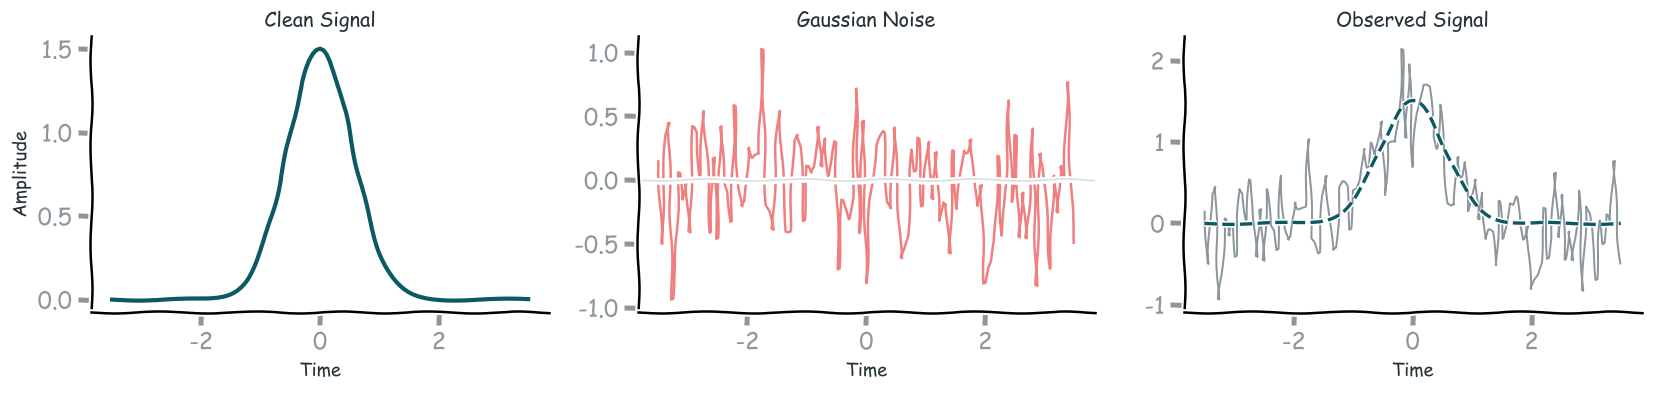

In [5]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 3.5)
)

# 1. Clean signal
axes[0].plot(
    t, x,
    color=TEAL,
    linewidth=2.5
)
axes[0].set_title("Clean Signal")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Amplitude")

# 2. Additive Gaussian noise
axes[1].plot(
    t, w1,
    color=RED,
    linewidth=1.5
)
axes[1].axhline(
    0,
    color=LIGHT_GRAY,
    linewidth=1
)
axes[1].set_title("Gaussian Noise")
axes[1].set_xlabel("Time")

# 3. Noisy observation
axes[2].plot(
    t, y1,
    color=GRAY,
    linewidth=1.2,
    label="Noisy observation"
)
axes[2].plot(
    t, x,
    color=TEAL,
    linewidth=2,
    linestyle="--",
    label="Clean signal"
)
axes[2].set_title("Observed Signal")
axes[2].set_xlabel("Time")
#axes[2].legend(frameon=False)

plt.tight_layout()
plt.show()

***Important Note**: We know the true amplitude because this is a simulation. In a real estimation problem, the true amplitude is unknown.*

### A Simple Approach: Peak-Based Estimation

Suppose we know the exact location of the pulse peak. Since our signal template is normalized such that:
$$
s[n_0]=1
$$
where $n_0$ is the known peak location, the observation at that sample is:
$$
y[n_0]=a+w[n_0]
$$
A simple amplitude estimate is therefore:
$$
\boxed{
\hat a_{\mathrm{peak}}=y[n_0]
}
$$
This estimator is intuitive: we use the measurement at the expected pulse peak to estimate the signal amplitude.

**However, there is a potential problem!**

The peak-based estimator uses only **one sample** from the entire observation. If the noise at that particular sample is large, the estimated amplitude may be inaccurate. all the other samples also contain information about the unknown amplitude.

**Can we use the entire waveform to obtain a better estimate?** This motivates maximum likelihood estimation.

**Note:** 
> We use the sample at the known peak location, not the maximum value of the noisy observation. These are different estimation methods.

In [6]:
# Peak-based amplitude estimation
def estimate_amplitude_peak(y, s):
    """
    Estimate signal amplitude using the observed
    sample at the known template peak.

    The template is assumed to have a nonzero peak.
    """

    peak_idx = np.argmax(s)

    return y[peak_idx] / s[peak_idx]


# Estimating amplitudes from both observations
a_peak_1 = estimate_amplitude_peak(y1, s)
a_peak_2 = estimate_amplitude_peak(y2, s)

print(f"True amplitude: {a_true:.4f}")
print()
print(f"Peak estimate (Observation 1): {a_peak_1:.4f}")
print(f"Peak estimate (Observation 2): {a_peak_2:.4f}")

True amplitude: 1.5000

Peak estimate (Observation 1): 0.6922
Peak estimate (Observation 2): 1.6053


### MLE

The peak-based estimator uses only one sample, but we know the expected waveform at every sample.

Maximum likelihood estimation selects the parameter value that maximizes the likelihood of the observed data: 
$$
\hat{a}_{\mathrm{ML}} =
\arg\max_a p(\mathbf{y}\mid a)
$$
For our Gaussian observation model, maximizing the likelihood is equivalent to minimizing the squared reconstruction error:
$$
\hat{a}_{\mathrm{ML}} =
\arg\min_a
\left\|\mathbf{y}-a\mathbf{s}\right\|_2^2
$$
The resulting estimator is:
$$
\boxed{
\hat{a}_{\mathrm{ML}} =
\frac{\mathbf{s}^T\mathbf{y}}
{\mathbf{s}^T\mathbf{s}}
}
$$
We will apply this estimator to two observations generated from the same underlying signal.

In [7]:
def estimate_amplitude_ml(y, s):

    numerator = np.dot(s, y)
    denominator = np.dot(s, s)

    return numerator / denominator


# ML estimates
a_ml_1 = estimate_amplitude_ml(y1, s)
a_ml_2 = estimate_amplitude_ml(y2, s)


# Comparing
print(f"True amplitude: {a_true:.4f}")
print()
print("Observation 1")
print(f"Peak estimate: {a_peak_1:.4f}")
print(f"ML estimate:   {a_ml_1:.4f}")
print()
print("Observation 2")
print(f"Peak estimate: {a_peak_2:.4f}")
print(f"ML estimate:   {a_ml_2:.4f}")

True amplitude: 1.5000

Observation 1
Peak estimate: 0.6922
ML estimate:   1.4726

Observation 2
Peak estimate: 1.6053
ML estimate:   1.6138


### Comparing the Two Estimators

We have now estimated the same unknown amplitude using two different methods.
* **Peak-based estimation:**
Uses only the observation at the known pulse peak.
* **Maximum likelihood estimation:**
Uses the entire waveform through its correlation with the known template.

Let's compare the reconstructed signals.For each estimator, we reconstruct the waveform using:
$$
\hat y[n]=\hat a\,s[n]
$$
The reconstruction shows what each estimated amplitude implies about the underlying signal.

> ***Q**: If the peak sample is strongly corrupted by noise, which estimator do you expect to reconstruct the clean signal more accurately?*

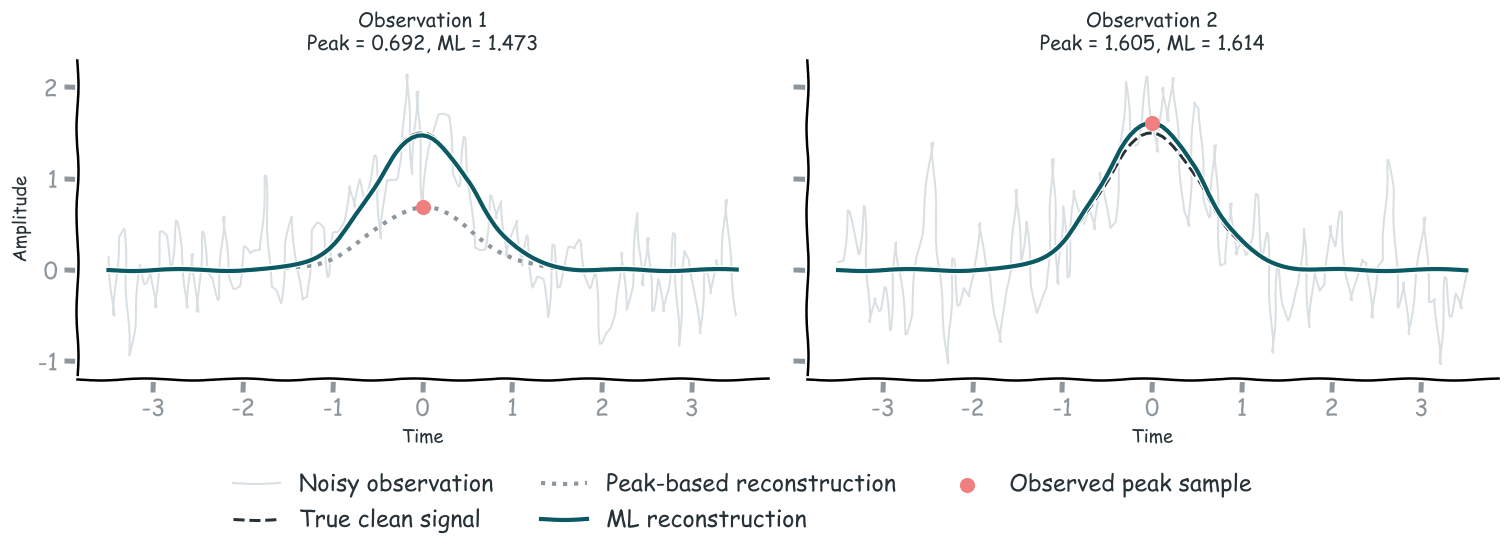

In [8]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    sharey=True
)

observations = [y1, y2]

peak_estimates = [
    a_peak_1,
    a_peak_2
]

ml_estimates = [
    a_ml_1,
    a_ml_2
]

for i, ax in enumerate(axes):

    y = observations[i]

    a_peak = peak_estimates[i]
    a_ml = ml_estimates[i]

    # Noisy observation
    ax.plot(
        t, y,
        color=LIGHT_GRAY,
        linewidth=1.2,
        label="Noisy observation"
    )

    # True clean signal
    ax.plot(
        t, x,
        color=DARK,
        linestyle="--",
        linewidth=1.8,
        label="True clean signal"
    )

    # Peak-based reconstruction
    ax.plot(
        t, a_peak * s,
        color=GRAY,
        linestyle=":",
        linewidth=2.5,
        label="Peak-based reconstruction"
    )

    # ML reconstruction
    ax.plot(
        t, a_ml * s,
        color=TEAL,
        linewidth=2.5,
        label="ML reconstruction"
    )

    # Highlight the observed peak sample
    ax.scatter(
        t[peak_idx],
        y[peak_idx],
        color=RED,
        s=65,
        zorder=5,
        label="Observed peak sample"
    )

    ax.set_title(
        f"Observation {i+1}\n"
        f"Peak = {a_peak:.3f}, ML = {a_ml:.3f}"
    )

    ax.set_xlabel("Time")

axes[0].set_ylabel("Amplitude")

# legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, -0.05)
)

plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

The peak-based estimator depends entirely on the noise at one sample. If that sample contains a large noise contribution, the resulting estimate may be inaccurate.

Maximum likelihood estimation combines information from the entire waveform. Because the signal template is known, ML can use the observations at different samples to estimate the amplitude.

The signal follows a predictable pattern across time. The Gaussian noise, however, fluctuates randomly from sample to sample. By combining observations according to the known template, ML can reduce the effect of independent measurement noise.

### Does ML always produce a better estimate?
However, this does not mean that ML always produces a better estimation. For a particular noise realization, the peak-based estimate may happen to be closer to the true amplitude. Under our assumed Gaussian model, ML has lower estimation variance than the peak-based estimator.

Both estimators are unbiased in this experiment.

> **Main takeaway:**
> **Knowledge of a signal's structure allows us to combine information across multiple samples rather than relying on a single noisy measurement.**

#### Visualizing Maximum Likelihood

So far, we have calculated the ML estimate directly using its closed-form expression.  
Now, we want to know  what  it actually means to maximize a likelihood function.  
For our Gaussian observation model:  
$$
y[n] = a\,s[n] + w[n]
$$
where
$$
\mathbf{w}
\sim
\mathcal{N}(\mathbf{0},\sigma^2\mathbf{I})
$$
the likelihood function is:
$$
p(\mathbf{y}\mid a) =
\frac{1}{(2\pi\sigma^2)^{N/2}}
\exp\left( -\frac{\|\mathbf{y}-a\mathbf{s}\|_2^2}
{2\sigma^2}
\right)
$$
Notice that the likelihood depends on the candidate amplitude $a$, and the observed data $\mathbf y$ remain fixed.  
The maximum likelihood estimate is the amplitude that maximizes this function.  
Equivalently, it minimizes the squared difference between the observation and the reconstructed signal.  
What we do is that we evaluate the likelihood for many candidate amplitudes and identify the value that produces the highest likelihood.  
For numerical stability, we will calculate the relative likelihood:
$$
L_{\mathrm{rel}}(a) =
\exp\left(
\ell(a) -
\max_{a'}\ell(a')
\right)
$$
where $\ell(a)$ is the log-likelihood:
$$
\ell(a) =
\log p(\mathbf{y}\mid a)
$$ 
$$
\ell(a) =
-\frac{N}{2}\log(2\pi\sigma^2) -
\frac{\|\mathbf{y}-a\mathbf{s}\|_2^2}
{2\sigma^2}
$$  
This rescales the maximum likelihood value to approximately one without changing the location of the maximum.  
***Important Note:** A likelihood function is not automatically a probability distribution over the parameter. Rescaling its maximum to one does not make it a normalized posterior density.*

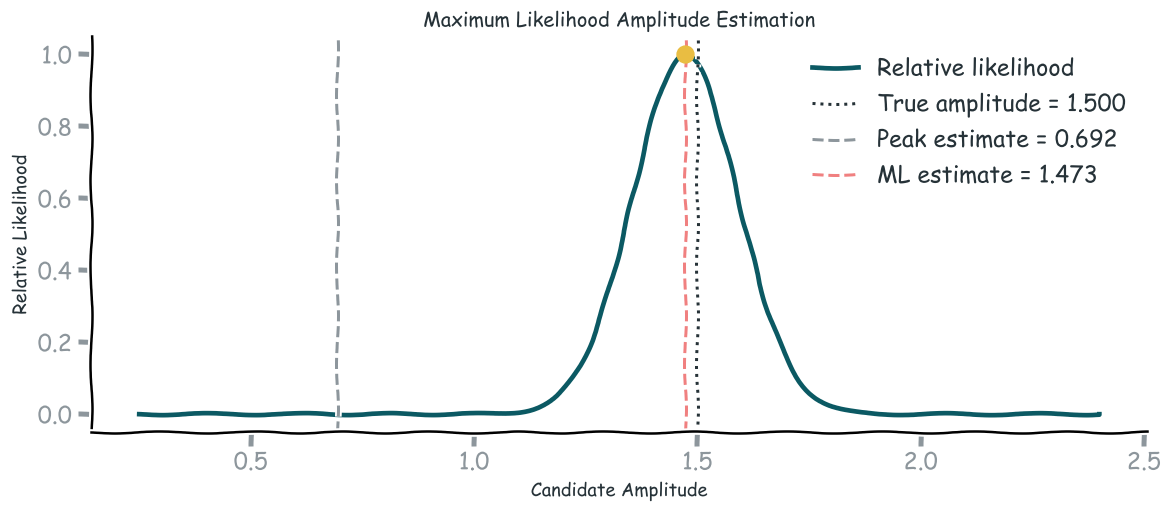

Closed-form ML estimate: 1.47261
Grid-search ML estimate: 1.47208


In [9]:
# amplitude values
a_candidates = np.linspace(
    0.25,
    2.4,
    900
)

# Evaluating squared reconstruction errors
predicted_signals = (
    a_candidates[:, None] * s[None, :]
)

squared_errors = np.sum(
    (y1[None, :] - predicted_signals)**2,
    axis=1
)

# Gaussian log-likelihood
log_likelihood = (
    -squared_errors / (2 * sigma_true**2)
)

# Relative likelihood
relative_likelihood = np.exp(
    log_likelihood - np.max(log_likelihood)
)

# ML estimate obtained by grid search
a_ml_grid = a_candidates[
    np.argmax(relative_likelihood)
]

# Visualization
fig, ax = plt.subplots(figsize=(10, 4.5))

# Likelihood
ax.plot(
    a_candidates,
    relative_likelihood,
    color=TEAL,
    linewidth=2.8,
    label="Relative likelihood"
)

# True amplitude
ax.axvline(
    a_true,
    color=DARK,
    linestyle=":",
    linewidth=1.8,
    label=f"True amplitude = {a_true:.3f}"
)

# Peak-based estimate
ax.axvline(
    a_peak_1,
    color=GRAY,
    linestyle="--",
    linewidth=1.8,
    label=f"Peak estimate = {a_peak_1:.3f}"
)

# ML estimate
ax.axvline(
    a_ml_1,
    color=RED,
    linestyle="--",
    linewidth=1.8,
    label=f"ML estimate = {a_ml_1:.3f}"
)

# Mark the likelihood maximum
ax.scatter(
    a_ml_grid,
    relative_likelihood.max(),
    color=YELLOW,
    s=100,
    zorder=5
)

ax.set_xlabel("Candidate Amplitude")
ax.set_ylabel("Relative Likelihood")

ax.set_title(
    "Maximum Likelihood Amplitude Estimation"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

print(
    f"Closed-form ML estimate: {a_ml_1:.5f}"
)
print(
    f"Grid-search ML estimate: {a_ml_grid:.5f}"
)

The likelihood function tells us how well different candidate amplitudes explain the observed data under our assumed statistical model. Values near the maximum correspond to candidate amplitudes that provide a relatively good explanation of the observation, and values far from the maximum correspond to poorer explanations under the model. The ML estimator selects:
$$
\boxed{
\hat{a}_{\mathrm{ML}} =
\arg\max_a p(\mathbf{y}\mid a)
}
$$
In our Gaussian model, this corresponds to minimizing the squared reconstruction error.  

### The Effect of Noise Variance

As previously mentioned, the likelihood function depends on the assumed noise variance. A larger noise variance means that larger deviations between the observed and predicted signals are considered more plausible, and a smaller noise variance means that deviations are penalized more strongly.

> ***Q:** Suppose we increase the assumed noise variance while keeping the observed data exactly the same, what happens to the likelihood function?*

Here, we  keep y1 fixed and only change the variance assumed by the likelihood model.

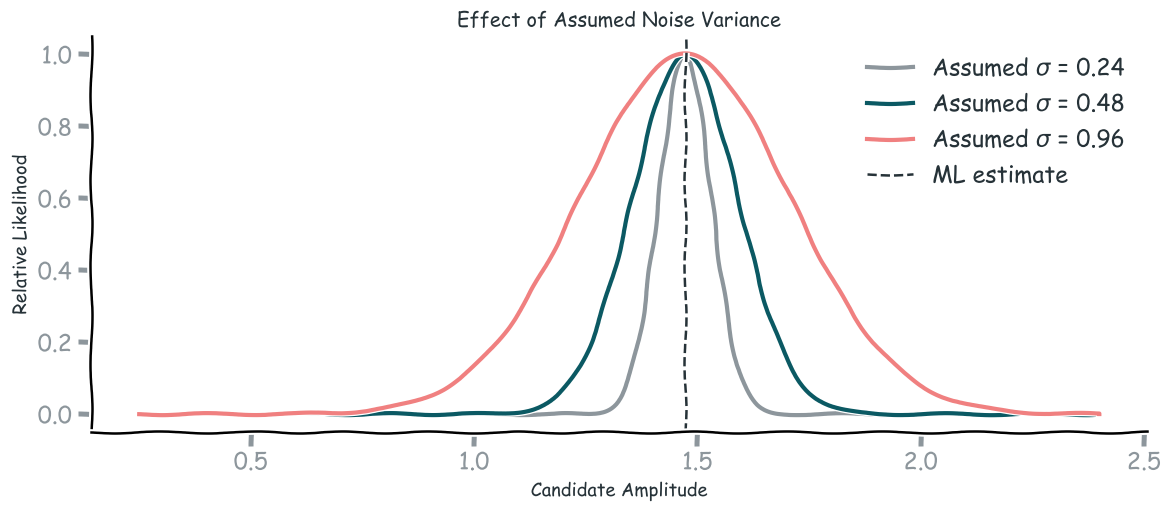

In [10]:
# Assumed noise standard deviations
sigma_assumed_values = [
    0.24,
    0.48,
    0.96
]

colors = [
    GRAY,
    TEAL,
    RED
]

fig, ax = plt.subplots(figsize=(10, 4.5))

for sigma_assumed, color in zip(
    sigma_assumed_values,
    colors
):

    # Log-likelihood
    log_L = (
        -squared_errors / (2 * sigma_assumed**2)
    )

    # Relative likelihood
    L_relative = np.exp(
        log_L - np.max(log_L)
    )

    ax.plot(
        a_candidates,
        L_relative,
        color=color,
        linewidth=2.5,
        label=rf"Assumed $\sigma$ = {sigma_assumed}"
    )

# ML estimate
ax.axvline(
    a_ml_1,
    color=DARK,
    linestyle="--",
    linewidth=1.5,
    label="ML estimate"
)

ax.set_xlabel("Candidate Amplitude")
ax.set_ylabel("Relative Likelihood")

ax.set_title(
    "Effect of Assumed Noise Variance"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

As we can see, increasing the assumed noise variance produces a broader relative likelihood curve, and decreasing the assumed noise variance produces a narrower curve. This reflects how sensitive the likelihood is to changes in the candidate amplitude. However, the ML estimate does not change. For this model, changing the assumed common noise variance does not change the location of the ML estimate when the observation remains fixed.
The reason is that the ML estimate is obtained by minimizing:
$$
\hat a_{\mathrm{ML}} =
\arg\min_a
\frac{1}{2\sigma^2}
\|\mathbf y-a\mathbf s\|_2^2
$$
Changing the assumed common noise variance only multiplies the objective by a positive constant.

Therefore, it does not change the location of the minimum.

### ML as a Geometric Projection

For additive white Gaussian noise, maximum likelihood amplitude estimation is equivalent to least-squares estimation.Geometrically, the estimator projects the observation vector onto the direction of the known signal template.The reconstructed signal is:
$$
\hat{\mathbf y} =
\hat a_{\mathrm{ML}}\mathbf s
$$
The residual is:
$$
\mathbf r =
\mathbf y-\hat{\mathbf y}
$$
or equivalently:
$$
\mathbf r =
\mathbf y-\hat a_{\mathrm{ML}}\mathbf s
$$
At the least-squares solution, the residual is orthogonal to the known signal template:
$$
\boxed{
\mathbf s^T\mathbf r=0
}
$$
This means that the residual has no component along the template direction.Otherwise, changing the estimated amplitude could further reduce the reconstruction error.

In [11]:
# ML reconstruction
y_ml = a_ml_1 * s

# Residual
residual = y1 - y_ml

# Inner product with signal template
inner_product = np.dot(s, residual)

print(f"ML estimate: {a_ml_1:.6f}")
print(
    "Inner product <s, residual>:",
    f"{inner_product:.12e}"
)
print(
    "Approximately orthogonal:",
    np.isclose(inner_product, 0, atol=1e-10)
)

ML estimate: 1.472605
Inner product <s, residual>: -9.875262210613e-15
Approximately orthogonal: True


### Conclusion

In this experiment, we investigated the problem of estimating the amplitude of a known signal from noisy observations.

Results: 

**1. A noisy measurement does not uniquely determine the true parameter.**

Different noise realizations generally produce different estimates.

**2. Using only one sample can be unreliable.**

The peak-based estimator is strongly affected by the noise at the selected sample.

**3. Maximum likelihood exploits the known signal structure.**

Under our Gaussian noise model, ML combines information from the entire waveform rather than relying on a single measurement.

**4. ML estimates correspond to likelihood maxima.**

For additive white Gaussian noise, maximum likelihood estimation is equivalent to least-squares estimation.

**5. Estimation and uncertainty are different concepts.**

The location of the ML estimate and the width of the likelihood describe different aspects of the estimation problem.


## Experiment 2: How Reliable Is Our Estimate?

In Experiment 1, we obtained an amplitude estimate from a particular noisy observation. But if we repeated the measurement thousands of times, each observation would contain a different realization of noise. Consequently, we would generally obtain a different amplitude estimate each time.

**How can we evaluate the reliability of an estimator across all these possible observations?**

### Monte Carlo Simulation

Monte Carlo methods use repeated random experiments to investigate the statistical properties of a system.

In our case, we will:

1. Keep the true signal amplitude fixed.
2. Generate many independent noise realizations.
3. Construct a new observation for each realization.
4. Calculate the ML estimate for each observation.
5. Analyze the distribution of the resulting estimates.

We will then compare our experimental results with theoretical predictions.

> ***Q:***
> *Suppose we estimate the same fixed amplitude from 5,000 independent noisy observations. What do you expect the resulting estimates to look like?*
> - *Will all estimates be identical?*
> - *Will they be distributed around the true amplitude?*
> - *Will some estimates be farther from the true amplitude than others?*


In [12]:
n_trials = 5000 # Number of independent Monte Carlo experiments

rng_mc = np.random.default_rng(2026)

# Known signal properties
signal_energy = np.dot(s, s)
clean_signal = a_true * s

# Generating independent Gaussian noise realizations
noise_mc = rng_mc.normal(
    loc=0,
    scale=sigma_true,
    size=(n_trials, len(s))
)

# Generate noisy observations
observations_mc = (
    clean_signal[None, :] + noise_mc
)

# Calculate ML estimates (Each row of observations_mc represents one observation)
a_ml_samples = (
    observations_mc @ s
) / signal_energy

# Display basic information
print("Monte Carlo Simulation")
print("-" * 40)
print(f"True amplitude: {a_true:.4f}")
print(f"Noise standard deviation: {sigma_true:.4f}")
print(f"Number of observations: {n_trials}")
print("\nFirst 10 ML estimates:")
print(np.round(a_ml_samples[:10], 4))

Monte Carlo Simulation
----------------------------------------
True amplitude: 1.5000
Noise standard deviation: 0.4800
Number of observations: 5000

First 10 ML estimates:
[1.5212 1.6341 1.6069 1.6955 1.403  1.363  1.5965 1.549  1.5622 1.2967]


**True parameter:**
The unknown quantity that we want to estimate. In our classical estimation experiment, the true amplitude $a$ is fixed.

**Estimator:**
A rule that maps observations to estimated parameter values. Before observing the data, the estimator is a random variable because it depends on random observations.

**Estimate:**
The numerical value produced by the estimator for one particular observation.


ML Estimator is random, why?

Recall the observation model:
$$
\mathbf y=a\mathbf s+\mathbf w
$$
Substituting this into the ML estimator gives:
$$
\hat a_{\mathrm{ML}} =
\frac{\mathbf s^T(a\mathbf s+\mathbf w)}
{\mathbf s^T\mathbf s}
$$
Therefore:
$$
\boxed{
\hat a_{\mathrm{ML}} =
a+
\frac{\mathbf s^T\mathbf w}
{\mathbf s^T\mathbf s}
}
$$
This equation separates the estimate into two components:
$$
\underbrace{\hat a_{\mathrm{ML}}}_{\text{Estimate}} =
\underbrace{a}_{\text{True Parameter}} +
\underbrace{
\frac{\mathbf s^T\mathbf w}{\mathbf s^T\mathbf s}
}_{\text{Estimation Error}}
$$
The true parameter remains fixed.The estimation error depends on the random noise realization.So, the ML estimates vary across repeated observations.

**Sampling Distribution:** The sampling distribution describes how an estimator behaves across repeated random observations.
We can approximate this distribution using the estimates obtained from our Monte Carlo simulation.

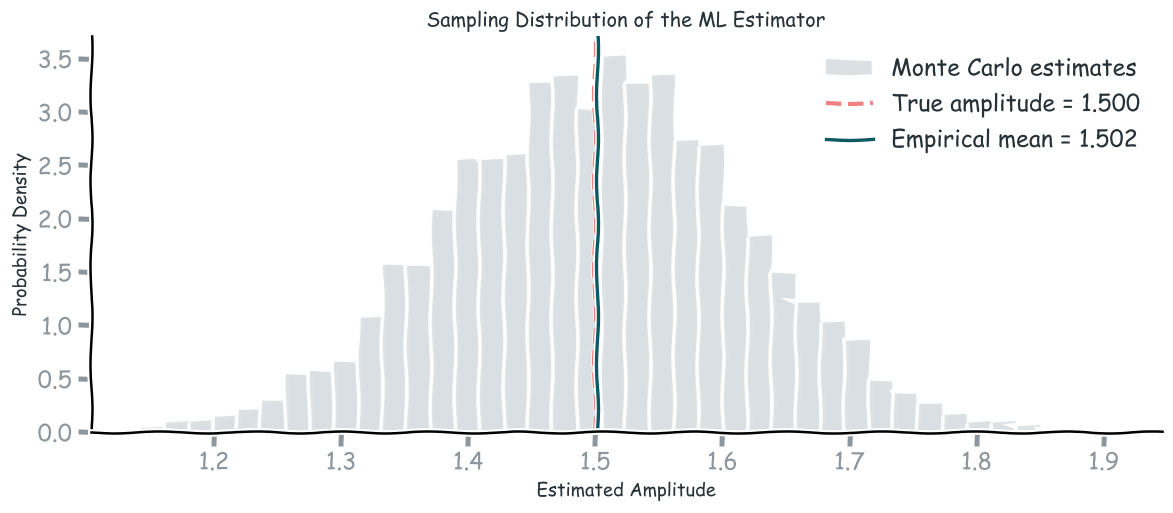

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))

# Histogram of ML estimates
ax.hist(
    a_ml_samples,
    bins=40,
    density=True,
    color=LIGHT_GRAY,
    edgecolor="white",
    alpha=0.9,
    label="Monte Carlo estimates"
)

# True amplitude
ax.axvline(
    a_true,
    color=RED,
    linestyle="--",
    linewidth=2.5,
    label=f"True amplitude = {a_true:.3f}"
)

# Empirical mean
empirical_mean = np.mean(a_ml_samples)

ax.axvline(
    empirical_mean,
    color=TEAL,
    linestyle="-",
    linewidth=2,
    label=f"Empirical mean = {empirical_mean:.3f}"
)

ax.set_xlabel("Estimated Amplitude")
ax.set_ylabel("Probability Density")

ax.set_title(
    "Sampling Distribution of the ML Estimator"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### Bias, Variance, and MSE

A single estimate does not tell us enough about an estimator's statistical performance. We need quantities that describe its behavior across repeated observations. Three particularly important quantities are **bias**, **variance**, and **mean squared error (MSE)**.


#### 1. Bias

Bias describes whether an estimator systematically overestimates or underestimates the true parameter.

$$
\boxed{
\operatorname{Bias}(\hat a) =
\mathbb E[\hat a]-a
}
$$

An estimator is unbiased if:

$$
\mathbb E[\hat a]=a
$$

For our Gaussian ML amplitude estimator:

$$
\mathbb E[\hat a_{\mathrm{ML}}]=a
$$

Therefore:

$$
\operatorname{Bias}(\hat a_{\mathrm{ML}})=0
$$


#### 2. Variance

Variance measures how much the estimates fluctuate around their expected value.

$$
\boxed{
\operatorname{Var}(\hat a) =
\mathbb E[
(\hat a-\mathbb E[\hat a])^2
]
}
$$

An estimator with high variance produces estimates that fluctuate substantially across different observations, and an estimator with low variance produces more concentrated estimates.

#### 3. Mean Squared Error (MSE)

MSE measures the expected squared difference between an estimate and the true parameter.

$$
\boxed{
\operatorname{MSE}(\hat a) =
\mathbb E[(\hat a-a)^2]
}
$$

For a scalar estimator:

$$
\boxed{
\operatorname{MSE}(\hat a) =
\operatorname{Bias}^2(\hat a) +
\operatorname{Var}(\hat a)
}
$$

This relationship is known as the **bias–variance decomposition** of mean squared error.

For an unbiased estimator:

$$
\operatorname{MSE}(\hat a) =
\operatorname{Var}(\hat a)
$$

#### Monte Carlo Estimation

Using $K$ independent Monte Carlo estimates, we can approximate these quantities.

Empirical mean:

$$
\bar a =
\frac{1}{K}
\sum_{k=1}^{K}\hat a^{(k)}
$$

Empirical bias:

$$
\widehat{\operatorname{Bias}} =
\bar a-a
$$

Sample variance:

$$
\widehat{\operatorname{Var}} =
\frac{1}{K-1}
\sum_{k=1}^{K}
(\hat a^{(k)}-\bar a)^2
$$

Empirical MSE:

$$
\widehat{\operatorname{MSE}} =
\frac{1}{K}
\sum_{k=1}^{K}
(\hat a^{(k)}-a)^2
$$

In [14]:
empirical_mean = np.mean(a_ml_samples)
empirical_bias = empirical_mean - a_true
empirical_variance = np.var(
    a_ml_samples,
    ddof=1
)
empirical_std = np.std(
    a_ml_samples,
    ddof=1
)

empirical_mse = np.mean(
    (a_ml_samples - a_true)**2
)

#  results
print("ML Estimator Performance")
print("-" * 45)

print(f"True amplitude:       {a_true:.6f}")
print(f"Empirical mean:       {empirical_mean:.6f}")
print(f"Empirical bias:       {empirical_bias:.6f}")

print()

print(f"Empirical variance:   {empirical_variance:.6f}")
print(f"Empirical std:        {empirical_std:.6f}")
print(f"Empirical MSE:        {empirical_mse:.6f}")

ML Estimator Performance
---------------------------------------------
True amplitude:       1.500000
Empirical mean:       1.501614
Empirical bias:       0.001614

Empirical variance:   0.013703
Empirical std:        0.117060
Empirical MSE:        0.013703


### How Accurate Can an Unbiased Estimator Be?

We have now measured the variance of our ML estimator using Monte Carlo simulation, but how can we determine whether this variance is theoretically good? Could another unbiased estimator have a substantially smaller variance?

This motivates the **Cramér–Rao Lower Bound (CRLB)**.


#### Fisher Information

Fisher information measures how strongly the probability distribution of the observations depends on an unknown parameter.
For a scalar parameter $a$, Fisher information can be defined as:
$$
\mathcal I(a) =
\mathbb E\left[
\left(
\frac{\partial}{\partial a}
\log p(\mathbf Y\mid a)
\right)^2
\right]
$$
under appropriate regularity conditions. Intuitively, greater Fisher information means that the observations are more informative about the unknown parameter.

For our Gaussian amplitude-estimation model:
$$
\mathbf Y=a\mathbf s+\mathbf W
$$
with:
$$
\mathbf W\sim\mathcal N(\mathbf 0,\sigma^2\mathbf I)
$$
the Fisher information is:
$$
\boxed{
\mathcal I(a) =
\frac{\mathbf s^T\mathbf s}{\sigma^2}
}
$$

#### Cramér–Rao Lower Bound

Under the standard regularity assumptions, the CRLB states that the variance of an unbiased estimator is bounded below by the inverse Fisher information:

$$
\boxed{
\operatorname{Var}(\hat a)
\geq
\frac{1}{\mathcal I(a)}
}
$$

For our signal model:

$$
\boxed{
\operatorname{Var}(\hat a)
\geq
\frac{\sigma^2}{\mathbf s^T\mathbf s}
}
$$


### What About the ML Estimator?

Recall:

$$
\hat a_{\mathrm{ML}} =
a+
\frac{\mathbf s^T\mathbf W}
{\mathbf s^T\mathbf s}
$$

Since the noise is Gaussian, the estimation error is also Gaussian. The sampling distribution of the ML estimator is:

$$
\boxed{
\hat a_{\mathrm{ML}}
\sim
\mathcal N\left(
a,
\frac{\sigma^2}{\mathbf s^T\mathbf s}
\right)
}
$$

Therefore:

$$
\boxed{
\operatorname{Var}(\hat a_{\mathrm{ML}}) =
\frac{\sigma^2}{\mathbf s^T\mathbf s} =
\mathrm{CRLB}
}
$$

The ML estimator achieves the CRLB in this linear Gaussian amplitude-estimation problem. Such an unbiased estimator is called **efficient**. 

What this means is that under our assumed model, the ML estimator achieves the minimum variance permitted by the usual CRLB for unbiased estimators. This does not mean that every ML estimator is efficient in every statistical problem.

**Experimental Question: Does the variance obtained from our Monte Carlo simulation agree with the theoretical CRLB?**

In [15]:
fisher_information = (
    signal_energy / sigma_true**2
)

crlb = 1 / fisher_information

theoretical_variance = (
    sigma_true**2 / signal_energy
)

# Compare theory and experiment
print("Theoretical vs. Experimental Results")
print("-" * 50)
print(f"Signal energy:        {signal_energy:.6f}")
print(f"Fisher information:   {fisher_information:.6f}")
print()
print(f"CRLB:                 {crlb:.6f}")
print(f"Theoretical variance: {theoretical_variance:.6f}")
print(f"Empirical variance:   {empirical_variance:.6f}")

# Relative difference
relative_error = abs(
    empirical_variance - theoretical_variance
) / theoretical_variance

print()
print(f"Relative difference:  {100 * relative_error:.2f}%")

Theoretical vs. Experimental Results
--------------------------------------------------
Signal energy:        16.711708
Fisher information:   72.533454

CRLB:                 0.013787
Theoretical variance: 0.013787
Empirical variance:   0.013703

Relative difference:  0.61%


### How Does Noise Affect Estimation Reliability?

We now know that the variance of the ML estimator is:
$$
\operatorname{Var}(\hat a_{\mathrm{ML}}) =
\frac{\sigma^2}{\mathbf s^T\mathbf s}
$$

The variance depends on two important quantities:
- The measurement noise variance.
- The energy of the known signal template.

For this experiment, we will keep the signal template and true amplitude unchanged.
We will only change the **actual noise variance used to generate the observations**.

> **Q:  What happens to the variance of the ML estimator?**
> 1. It remains unchanged.
> 2. It doubles.
> 3. It becomes four times larger.
> 4. It cannot be determined.

Now, for several noise levels, we will:

1. Generate thousands of independent noisy observations.
2. Estimate the amplitude using ML.
3. Calculate the empirical estimator variance.
4. Calculate the corresponding theoretical CRLB.
5. Compare the results.

The observation model and signal template will remain the same throughout.

In [16]:
# Effect of Actual Noise Variance

# Noise standard deviations to investigate
sigma_values = np.array([
    0.20,
    0.32,
    0.48,
    0.65,
    0.80,
    1.00
])

rng_noise = np.random.default_rng(2027)

empirical_variances = []
theoretical_crlbs = []
empirical_mses = []

# Monte Carlo experiments
for sigma in sigma_values:

    # Generate independent noise realizations
    noise = rng_noise.normal(
        loc=0,
        scale=sigma,
        size=(n_trials, len(s))
    )

    # Generate noisy observations
    observations = (
        clean_signal[None, :] + noise
    )

    # ML amplitude estimates
    estimates = (
        observations @ s
    ) / signal_energy

    empirical_var = np.var(
        estimates,
        ddof=1
    )

    empirical_mse_sigma = np.mean(
        (estimates - a_true)**2
    )

    theoretical_crlb = (
        sigma**2 / signal_energy
    )

    empirical_variances.append(empirical_var)
    empirical_mses.append(empirical_mse_sigma)
    theoretical_crlbs.append(theoretical_crlb)

# Convert results to NumPy arrays
empirical_variances = np.array(
    empirical_variances
)

empirical_mses = np.array(
    empirical_mses
)

theoretical_crlbs = np.array(
    theoretical_crlbs
)

noise_variances = sigma_values**2

# results
print(
    f"{'Noise Std':<12}"
    f"{'Noise Var':<12}"
    f"{'Empirical Var':<17}"
    f"{'CRLB':<12}"
)

print("-" * 55)

for i in range(len(sigma_values)):

    print(
        f"{sigma_values[i]:<12.3f}"
        f"{noise_variances[i]:<12.4f}"
        f"{empirical_variances[i]:<17.6f}"
        f"{theoretical_crlbs[i]:<12.6f}"
    )

Noise Std   Noise Var   Empirical Var    CRLB        
-------------------------------------------------------
0.200       0.0400      0.002402         0.002394    
0.320       0.1024      0.006000         0.006127    
0.480       0.2304      0.013748         0.013787    
0.650       0.4225      0.025362         0.025282    
0.800       0.6400      0.038028         0.038297    
1.000       1.0000      0.059127         0.059838    


### Visualizing Estimation Uncertainty

We have now investigated the ML estimator in two complementary ways.
1. we generated many observations at a fixed noise level and examined the distribution of the resulting estimates.
2. we repeated the experiment at different noise levels and compared the empirical estimator variance with the theoretical CRLB.

The following visualization combines these results.

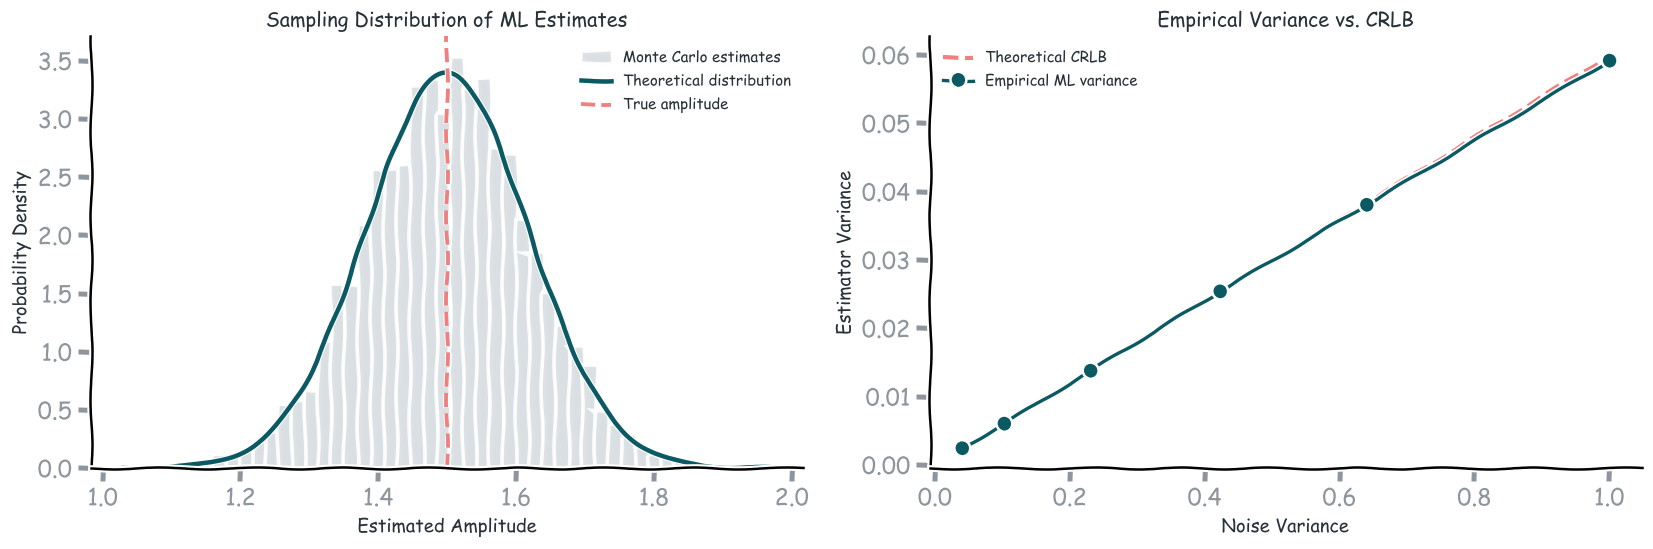

In [17]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.8)
)

# Sampling Distribution
ax = axes[0]

# Histogram
ax.hist(
    a_ml_samples,
    bins=40,
    density=True,
    color=LIGHT_GRAY,
    edgecolor="white",
    alpha=0.9,
    label="Monte Carlo estimates"
)

# Theoretical Gaussian distribution
theoretical_std = np.sqrt(
    theoretical_variance
)

a_grid = np.linspace(
    a_true - 4 * theoretical_std,
    a_true + 4 * theoretical_std,
    500
)

gaussian_pdf = (
    1 / (np.sqrt(2 * np.pi) * theoretical_std)
) * np.exp(
    -0.5 * (
        (a_grid - a_true) / theoretical_std
    )**2
)

ax.plot(
    a_grid,
    gaussian_pdf,
    color=TEAL,
    linewidth=2.7,
    label="Theoretical distribution"
)

# True amplitude
ax.axvline(
    a_true,
    color=RED,
    linestyle="--",
    linewidth=2.3,
    label="True amplitude"
)

ax.set_xlabel("Estimated Amplitude")
ax.set_ylabel("Probability Density")

ax.set_title(
    "Sampling Distribution of ML Estimates"
)

ax.legend(
    frameon=False,
    fontsize=9
)

# Empirical Variance vs. CRLB
ax = axes[1]

# Theoretical CRLB
ax.plot(
    noise_variances,
    theoretical_crlbs,
    color=RED,
    linestyle="--",
    linewidth=2.5,
    label="Theoretical CRLB"
)

# Empirical variance
ax.plot(
    noise_variances,
    empirical_variances,
    color=TEAL,
    marker="o",
    markersize=7,
    linewidth=2,
    label="Empirical ML variance"
)

ax.set_xlabel("Noise Variance")
ax.set_ylabel("Estimator Variance")

ax.set_title(
    "Empirical Variance vs. CRLB"
)

ax.legend(
    frameon=False,
    fontsize=9
)

fig.tight_layout()

plt.show()


**Left Panel — Sampling Distribution**

The histogram shows ML amplitude estimates obtained from repeated noisy observations. We also display the theoretical sampling distribution:
$$
\hat a_{\mathrm{ML}}
\sim
\mathcal N\left(
a,
\frac{\sigma^2}{\mathbf s^T\mathbf s}
\right)
$$

**Right Panel — Variance and CRLB**

We compare:
$$
\widehat{\operatorname{Var}}(\hat a_{\mathrm{ML}})
$$
with:
$$
\mathrm{CRLB} =
\frac{\sigma^2}{\mathbf s^T\mathbf s}
$$
for several measurement noise levels.

# Part II: When Maximum Likelihood Becomes Unreliable

## Experiment 3: Estimating Two Overlapping Signal Components

In Experiments 1 and 2, we estimated the amplitude of a single known signal:
$$
y[n]=a\,s[n]+w[n]
$$
We found that the Maximum Likelihood estimator is unbiased and achieves the Cramér–Rao lower bound under our linear Gaussian observation model. However, that problem involved only one unknown parameter.

**What happens when our observation contains multiple signal components?**

Consider a measurement consisting of two known waveforms with unknown amplitudes:
$$
\boxed{
y[n] =
a_1s_1[n] +
a_2s_2[n] +
w[n]
}
$$
where:
- $s_1[n]$ and $s_2[n]$ are known signal templates.
- $a_1$ and $a_2$ are unknown amplitudes.
- $w[n]$ is additive white Gaussian noise.
- $y[n]$ is the observed signal.

We assume:
$$
w[n]\overset{\mathrm{i.i.d.}}{\sim}\mathcal N(0,\sigma^2)
$$
Our objective is now to estimate two parameters:
$$
\mathbf a=
\begin{bmatrix}
a_1\\
a_2
\end{bmatrix}
$$

### Signals

We will use two Gaussian-shaped pulses:
$$
s_1(t) =
\exp\left(
-\frac{(t+\Delta/2)^2}{2b^2}
\right)
$$

$$
s_2(t) =
\exp\left(
-\frac{(t-\Delta/2)^2}{2b^2}
\right)
$$
where:
- $b$ controls the width of the pulses.
- $\Delta$ controls the separation between their centers.

By changing $\Delta$, we can control how much the two signal components overlap.

We will investigate 3 situations:

1. **Separated pulses**

The two signals are sufficiently different to distinguish their contributions.

2. **Overlapping pulses**

The signals are highly similar, making their individual amplitudes difficult to estimate.

3. **Identical pulses**

The signals become identical, and their individual amplitudes can no longer be uniquely identified.

> ***Q:** If two signals become identical, can we still estimate their individual amplitudes? What about reconstructing their combined waveform?*

#### Generate Gaussian Pulses

In [18]:
# True parameters
a_true_pair = np.array([1.0, 0.7])

sigma_overlap = sigma_true

# Define two Gaussian signal templates
def make_pulse_matrix(separation, t, width):


    s1 = np.exp(
        -0.5 * ((t + separation / 2) / width)**2
    )

    s2 = np.exp(
        -0.5 * ((t - separation / 2) / width)**2
    )

    S = np.column_stack([s1, s2])

    return S

# Three scenarios
separations = {
    "Separated": 2.0,
    "Overlap": 0.2,
    "Identical": 0.00
}

rng_overlap = np.random.default_rng(42)

shared_noise = rng_overlap.normal(
    0,
    sigma_overlap,
    size=len(t)
)

# observations
case_data = {}

for name, separation in separations.items():

    # Signal matrix
    S = make_pulse_matrix(
        separation,
        t,
        pulse_width
    )

    x = S @ a_true_pair

    y = x + shared_noise

    case_data[name] = {
        "S": S,
        "x": x,
        "y": y,
        "separation": separation
    }

print("True amplitudes:", a_true_pair)
print("Noise standard deviation:", sigma_overlap)
print("Number of scenarios:", len(case_data))

True amplitudes: [1.  0.7]
Noise standard deviation: 0.48
Number of scenarios: 3


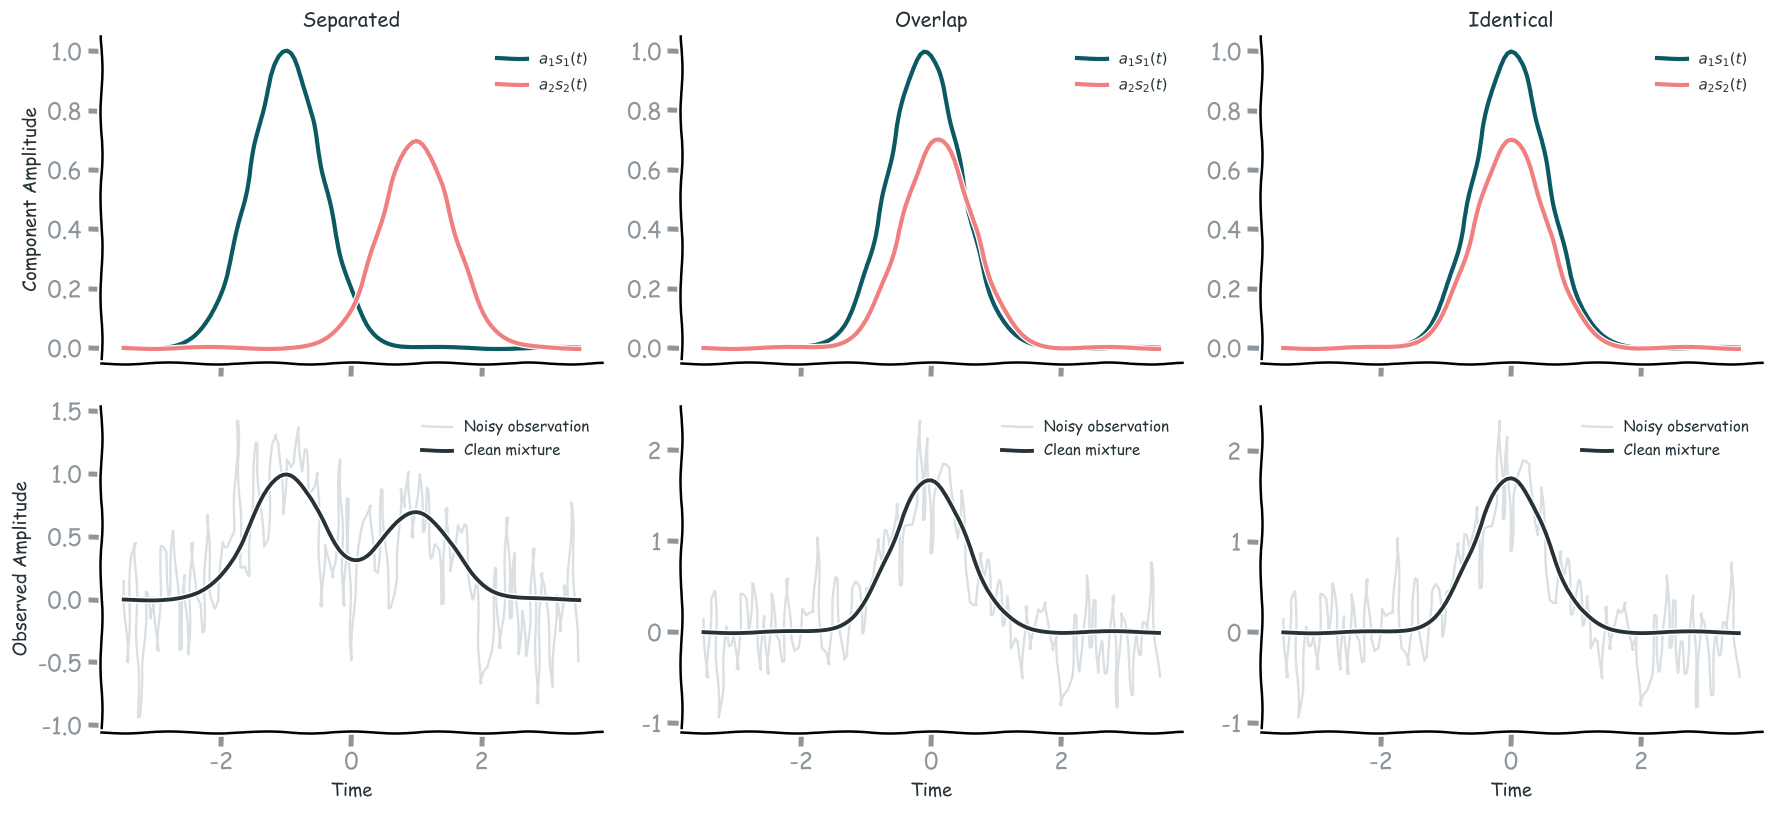

In [19]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 7),
    sharex=True
)

for col, (name, data) in enumerate(case_data.items()):

    S = data["S"]
    x = data["x"]
    y = data["y"]

    ax = axes[0, col]

    ax.plot(
        t,
        a_true_pair[0] * S[:, 0],
        color=TEAL,
        linewidth=2.5,
        label=r"$a_1s_1(t)$"
    )

    ax.plot(
        t,
        a_true_pair[1] * S[:, 1],
        color=RED,
        linewidth=2.5,
        label=r"$a_2s_2(t)$"
    )

    ax.set_title(name)

    if col == 0:
        ax.set_ylabel("Component Amplitude")

    ax.legend(frameon=False, fontsize=9)

    ax = axes[1, col]

    ax.plot(
        t,
        y,
        color=LIGHT_GRAY,
        linewidth=1.4,
        label="Noisy observation"
    )

    ax.plot(
        t,
        x,
        color=DARK,
        linewidth=2.3,
        label="Clean mixture"
    )

    ax.set_xlabel("Time")

    if col == 0:
        ax.set_ylabel("Observed Amplitude")

    ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

### Maximum Likelihood with Two Unknown Amplitudes

We can write our observation model in matrix form:
$$
\boxed{
\mathbf y=\mathbf S\mathbf a+\mathbf w
}
$$
where:
$$
\mathbf S=
\begin{bmatrix}
s_1[0] & s_2[0]\\
s_1[1] & s_2[1]\\
\vdots & \vdots\\
s_1[N-1] & s_2[N-1]
\end{bmatrix}
$$
and:
$$
\mathbf a=
\begin{bmatrix}
a_1\\
a_2
\end{bmatrix}
$$
The two columns of $\mathbf S$ represent the known signal templates, and the entries of $\mathbf a$ are the unknown amplitudes.


##### Maximum Likelihood Estimation

Under additive white Gaussian noise:

$$
\mathbf w\sim\mathcal N(\mathbf 0,\sigma^2\mathbf I)
$$

Maximum likelihood estimation is equivalent to minimizing squared reconstruction error:

$$
\boxed{
\hat{\mathbf a}_{\mathrm{ML}} =
\arg\min_{\mathbf a}
\|\mathbf y-\mathbf S\mathbf a\|_2^2
}
$$

If the columns of $\mathbf S$ are linearly independent, the ML solution is unique:

$$
\boxed{
\hat{\mathbf a}_{\mathrm{ML}} =
(\mathbf S^T\mathbf S)^{-1}
\mathbf S^T\mathbf y
}
$$

This is the multivariate extension of the estimator used in Experiment 1.

In [20]:
def estimate_amplitudes_ml(y, S):

    a_hat, residuals, rank, singular_values = (
        np.linalg.lstsq(S, y, rcond=None)
    )

    return a_hat, rank


# Estimate amplitudes
for name, data in case_data.items():

    S = data["S"]
    y = data["y"]

    # ML / least-squares solution
    a_hat, rank = estimate_amplitudes_ml(y, S)

    # Reconstructed waveform
    y_hat = S @ a_hat

    data["a_hat"] = a_hat
    data["y_hat"] = y_hat
    data["rank"] = rank

    print(f"\n{name}")
    print("-" * 40)

    print("True amplitudes:     ", a_true_pair)
    print("Returned coefficients:", np.round(a_hat, 4))
    print("Matrix rank:         ", rank)

    if rank < 2:
        print(
            "WARNING: Individual amplitudes "
            "are not uniquely identifiable."
        )


Separated
----------------------------------------
True amplitudes:      [1.  0.7]
Returned coefficients: [1.0776 0.6147]
Matrix rank:          2

Overlap
----------------------------------------
True amplitudes:      [1.  0.7]
Returned coefficients: [1.1984 0.4742]
Matrix rank:          2

Identical
----------------------------------------
True amplitudes:      [1.  0.7]
Returned coefficients: [0.8363 0.8363]
Matrix rank:          1


 ### A Good Reconstruction Is Not Always a Good Estimate

We have estimated the amplitudes of two overlapping signal components.
But how should we evaluate the result?

There are two different questions:

**1. Did we estimate the underlying parameters accurately?**

**2. Did we reconstruct the observed signal accurately?**


#### Parameter Estimation Error

In our simulation, the true amplitude vector is known:

$$
\mathbf a=
\begin{bmatrix}
a_1\\
a_2
\end{bmatrix}
$$

We can evaluate parameter estimation error using:

$$
\boxed{
E_{\mathrm{parameter}} =
\|\hat{\mathbf a}-\mathbf a\|_2
}
$$

A smaller value indicates more accurate recovery of the underlying amplitudes.

#### Signal Reconstruction

The clean signal is:
$$
\mathbf x=\mathbf S\mathbf a
$$
The reconstructed signal is:
$$
\hat{\mathbf x} =
\mathbf S\hat{\mathbf a}
$$

We can evaluate the relative reconstruction error against the clean signal:

$$
\boxed{
E_{\mathrm{reconstruction}} =
\frac{
\|\hat{\mathbf x}-\mathbf x\|_2
}{
\|\mathbf x\|_2
}
}
$$

This measures how closely the estimated parameters reproduce the underlying clean waveform.

We can also calculate the residual relative to the observed data:
$$
\mathbf r =
\mathbf y-\hat{\mathbf x}
$$

However, these two comparisons are different. The observed signal contains noise, while the clean signal does not.

> **Q: Can two substantially different amplitude combinations generate nearly identical waveforms?**
> If the signal templates are highly similar, the answer may be yes.

#### Compare Parameter Estimates and Reconstruction

Overlapping Signals
---------------------------------------------
True amplitudes:      [1.  0.7]
ML amplitudes:        [1.1984 0.4742]

Parameter error:     0.3006
Relative clean-signal reconstruction error: 3.59%


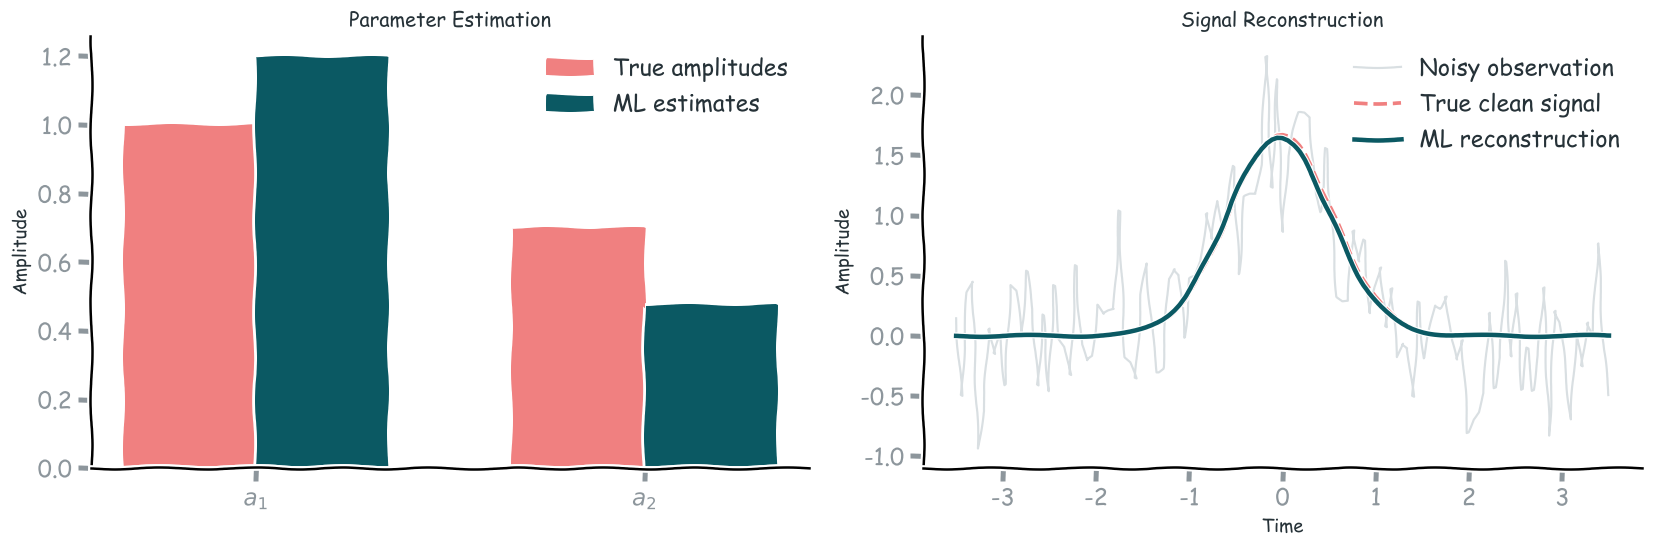

In [21]:
data = case_data["Overlap"]

S = data["S"]
x = data["x"]
y = data["y"]

a_hat = data["a_hat"]
y_hat = data["y_hat"]

# errors
parameter_error = np.linalg.norm(
    a_hat - a_true_pair
)

relative_reconstruction_error = (
    np.linalg.norm(y_hat - x)
    / np.linalg.norm(x)
)

print("Overlapping Signals")
print("-" * 45)

print("True amplitudes:     ", a_true_pair)
print("ML amplitudes:       ", np.round(a_hat, 4))

print()
print(f"Parameter error:     {parameter_error:.4f}")

print(
    "Relative clean-signal reconstruction error:",
    f"{100 * relative_reconstruction_error:.2f}%"
)

# Visualization
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.8)
)

#  True vs Estimated Parameters
ax = axes[0]

positions = np.arange(2)
bar_width = 0.34

ax.bar(
    positions - bar_width / 2,
    a_true_pair,
    width=bar_width,
    color=RED,
    label="True amplitudes"
)

ax.bar(
    positions + bar_width / 2,
    a_hat,
    width=bar_width,
    color=TEAL,
    label="ML estimates"
)

ax.set_xticks(positions)
ax.set_xticklabels([r"$a_1$", r"$a_2$"])

ax.set_ylabel("Amplitude")

ax.set_title(
    "Parameter Estimation"
)

ax.axhline(
    0,
    color=LIGHT_GRAY,
    linewidth=1
)

ax.legend(frameon=False)

# RIGHT — Signal Reconstruction
ax = axes[1]

ax.plot(
    t,
    y,
    color=LIGHT_GRAY,
    linewidth=1.3,
    label="Noisy observation"
)

ax.plot(
    t,
    x,
    color=RED,
    linestyle="--",
    linewidth=2.2,
    label="True clean signal"
)

ax.plot(
    t,
    y_hat,
    color=TEAL,
    linewidth=2.7,
    label="ML reconstruction"
)

ax.set_xlabel("Time")
ax.set_ylabel("Amplitude")

ax.set_title(
    "Signal Reconstruction"
)

ax.legend(frameon=False)

plt.tight_layout()

fig.savefig(
    "MLSP_Week1_Experiment3_Reconstruction.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Why Can Parameter Estimates Be Wrong While Reconstruction Is Accurate?

Consider the reconstructed signal:
$$
\hat{\mathbf x} =
\hat a_1\mathbf s_1 +
\hat a_2\mathbf s_2
$$
When the two templates are highly similar, their contributions become difficult to distinguish:
$$
\mathbf s_1\approx\mathbf s_2
$$

For example, increasing $\hat a_1$ while decreasing $\hat a_2$ may cause only a small change in the reconstructed waveform. Therefore, substantially different amplitude combinations can produce nearly identical signals.


What this means is that a small reconstruction error does not necessarily imply a small parameter estimation error. This distinction is particularly important when the objective is to interpret the underlying parameters rather than reproduce the measurements.

In Machine Learning:  
A machine learning model may achieve a good reconstruction loss while learning parameters that are poorly determined by the available observations. This can occur when multiple parameter configurations produce similar predictions.

 **Good predictive or reconstruction performance does not automatically guarantee accurate or uniquely identifiable parameters**.

#### Identical Pulses Scenario

Suppose the two signal templates become identical:
$$
\mathbf s_1=\mathbf s_2=\mathbf s
$$
Our observation model becomes:
$$
\mathbf y =
a_1\mathbf s +
a_2\mathbf s +
\mathbf w
$$
Factoring out the common waveform:
$$
\boxed{
\mathbf y =
(a_1+a_2)\mathbf s +
\mathbf w
}
$$

Notice that the observation depends only on the sum:
$$
c=a_1+a_2
$$
This means that different amplitude combinations can produce the same clean signal.

For example:
$$
(a_1,a_2)=(1.0,0.7)
$$
and:
$$
(a_1,a_2)=(0.2,1.5)
$$
both satisfy:
$$
a_1+a_2=1.7
$$
So both generate the same clean waveform.

We can estimate the combined amplitude:
$$
\boxed{
c=a_1+a_2
}
$$
But we cannot uniquely determine $a_1$ and $a_2$ separately from these observations. This is an example of **parameter nonidentifiability**.

**Identifiability:** 
A parameter is identifiable when different parameter values correspond to distinguishable probability distributions of the observations. If multiple parameter combinations produce the same observation distribution, those parameters are not identifiable.
In our identical-pulse example, the likelihood depends on $a_1$ and $a_2$ only through their sum. Therefore, infinitely many amplitude pairs produce the same likelihood.

In [22]:
data = case_data["Identical"]

S_identical = data["S"]
y_identical = data["y"]

# Two different parameter combinations
a_pair_1 = np.array([1.0, 0.7])
a_pair_2 = np.array([0.2, 1.5])

# Generate clean waveforms
x_pair_1 = S_identical @ a_pair_1
x_pair_2 = S_identical @ a_pair_2

difference = np.linalg.norm(
    x_pair_1 - x_pair_2
)

print("Parameter combination 1:", a_pair_1)
print("Parameter combination 2:", a_pair_2)

print()
print(f"Waveform difference: {difference:.12e}")

print(
    "Are the waveforms identical?",
    np.allclose(x_pair_1, x_pair_2)
)

# Estimate the identifiable sum
s_identical = S_identical[:, 0]

c_ml = (
    np.dot(s_identical, y_identical)
    / np.dot(s_identical, s_identical)
)

print()
print(f"True amplitude sum: {np.sum(a_true_pair):.4f}")
print(f"Estimated sum:      {c_ml:.4f}")

# Different ML solutions with the same amplitude sum
candidate_pairs = [
    np.array([c_ml, 0.0]),
    np.array([c_ml / 2, c_ml / 2]),
    np.array([0.0, c_ml])
]

print("\nDifferent amplitude pairs with identical fits:")

for pair in candidate_pairs:

    reconstruction = S_identical @ pair

    residual_norm = np.linalg.norm(
        y_identical - reconstruction
    )

    print(
        f"a = {np.round(pair, 4)}, "
        f"Residual norm = {residual_norm:.6f}"
    )

Parameter combination 1: [1.  0.7]
Parameter combination 2: [0.2 1.5]

Waveform difference: 6.577946023660e-16
Are the waveforms identical? True

True amplitude sum: 1.7000
Estimated sum:      1.6726

Different amplitude pairs with identical fits:
a = [1.6726 0.    ], Residual norm = 4.149732
a = [0.8363 0.8363], Residual norm = 4.149732
a = [0.     1.6726], Residual norm = 4.149732


### How Does Signal Overlap Affect Estimation Reliability?

So far, we have compared a few individual observations. But an estimator's performance should not be judged from only one noise realization. We will now investigate how the estimation error changes statistically as the two signals become more similar.


#### Measuring Signal Similarity

One way to quantify similarity between the two templates is their normalized inner product:
$$
\boxed{
\rho =
\frac{
\mathbf s_1^T\mathbf s_2
}{
\|\mathbf s_1\|_2
\|\mathbf s_2\|_2
}
}
$$
For our positive Gaussian pulses:
- Values near zero indicate relatively little overlap.
- Values near one indicate highly similar waveforms.
- A value of one occurs when the normalized templates are identical.

For the two-parameter Gaussian model:
$$
\mathbf y=\mathbf S\mathbf a+\mathbf w
$$
the Fisher information matrix is:
$$
\boxed{
\mathcal I(\mathbf a) =
\frac{\mathbf S^T\mathbf S}{\sigma^2}
}
$$
When the two signal templates become highly similar, the columns of $\mathbf S$ become nearly linearly dependent. this makes the estimation problem poorly conditioned.
For a full-column-rank matrix $\mathbf S$, the covariance of the ML estimator is:
$$
\boxed{
\operatorname{Cov}(\hat{\mathbf a}_{\mathrm{ML}}) =
\sigma^2(\mathbf S^T\mathbf S)^{-1}
}
$$
As the columns become nearly dependent, uncertainty in some combinations of the amplitudes can become very large.
At exact linear dependence, the matrix is singular and the individual parameters are not identifiable.

#### Monte Carlo Investigation


We will examine several pulse separations.
For each separation, we will:
1. Generate many noisy observations.
2. Estimate the two amplitudes using ML.
3. Calculate the parameter estimation error.
4. Calculate the reconstructed clean-signal error.
5. Compare the errors as the pulse separation decreases.

***Q: As the pulses become more similar, what happens to the accuracy of the individual amplitude estimates?***
*Will the signal reconstruction error necessarily increase by the same amount?*

In [23]:
# Monte Carlo Study — Increasing Signal Overlap

separation_values = np.array([
    1.80,
    1.20,
    0.80,
    0.50,
    0.30,
    0.20,
    0.14,
    0.10,
    0.08,
    0.06,
    0.04
])

n_trials_overlap = 1000    # Number of Monte Carlo trials

rng_sweep = np.random.default_rng(2030)

# Shared noise realizations
noise_sweep = rng_sweep.normal(
    loc=0,
    scale=sigma_overlap,
    size=(n_trials_overlap, len(t))
)



parameter_rmse = []
reconstruction_rmse = []
template_correlations = []
condition_numbers = []

# Monte Carlo experiments
for separation in separation_values:

    S = make_pulse_matrix(
        separation,
        t,
        pulse_width
    )

    x = S @ a_true_pair

    Y = x[None, :] + noise_sweep

    # ML estimates for all observations
    estimates = np.linalg.lstsq(
        S,
        Y.T,
        rcond=None
    )[0].T

    # Parameter estimation error
    parameter_errors = (
        estimates - a_true_pair[None, :]
    )

    param_rmse = np.sqrt(
        np.mean(
            np.sum(parameter_errors**2, axis=1)
        )
    ) / np.linalg.norm(a_true_pair)

    parameter_rmse.append(param_rmse)

    # Signal reconstruction error
    reconstructed_signals = estimates @ S.T

    reconstruction_errors = (
        reconstructed_signals - x[None, :]
    )

    # Relative root-mean-square reconstruction error
    recon_rmse = np.sqrt(
        np.mean(
            np.sum(reconstruction_errors**2, axis=1)
        )
    ) / np.linalg.norm(x)

    reconstruction_rmse.append(recon_rmse)

    # Template similarity
    s1 = S[:, 0]
    s2 = S[:, 1]

    correlation = (
        np.dot(s1, s2)
        / (np.linalg.norm(s1) * np.linalg.norm(s2))
    )

    template_correlations.append(correlation)

    # Condition number
    condition_numbers.append(
        np.linalg.cond(S)
    )

parameter_rmse = np.array(parameter_rmse)
reconstruction_rmse = np.array(reconstruction_rmse)

template_correlations = np.array(
    template_correlations
)

condition_numbers = np.array(
    condition_numbers
)

# Display a summary
print(
    f"{'Separation':<14}"
    f"{'Correlation':<15}"
    f"{'Condition':<15}"
    f"{'Param. RMSE':<15}"
    f"{'Recon. RMSE':<15}"
)

print("-" * 74)

for i in range(len(separation_values)):

    print(
        f"{separation_values[i]:<14.3f}"
        f"{template_correlations[i]:<15.5f}"
        f"{condition_numbers[i]:<15.2f}"
        f"{parameter_rmse[i]:<15.4f}"
        f"{reconstruction_rmse[i]:<15.4f}"
    )

Separation    Correlation    Condition      Param. RMSE    Recon. RMSE    
--------------------------------------------------------------------------
1.800         0.06872        1.07           0.1340         0.1298         
1.200         0.30420        1.37           0.1413         0.1194         
0.800         0.58924        1.97           0.1666         0.1091         
0.500         0.81334        3.12           0.2313         0.1025         
0.300         0.92832        5.19           0.3619         0.0995         
0.200         0.96748        7.78           0.5318         0.0986         
0.140         0.98393        11.11          0.7534         0.0982         
0.100         0.99177        15.56          1.0506         0.0980         
0.080         0.99472        19.45          1.3113         0.0979         
0.060         0.99703        25.93          1.7464         0.0979         
0.040         0.99868        38.89          2.6174         0.0978         


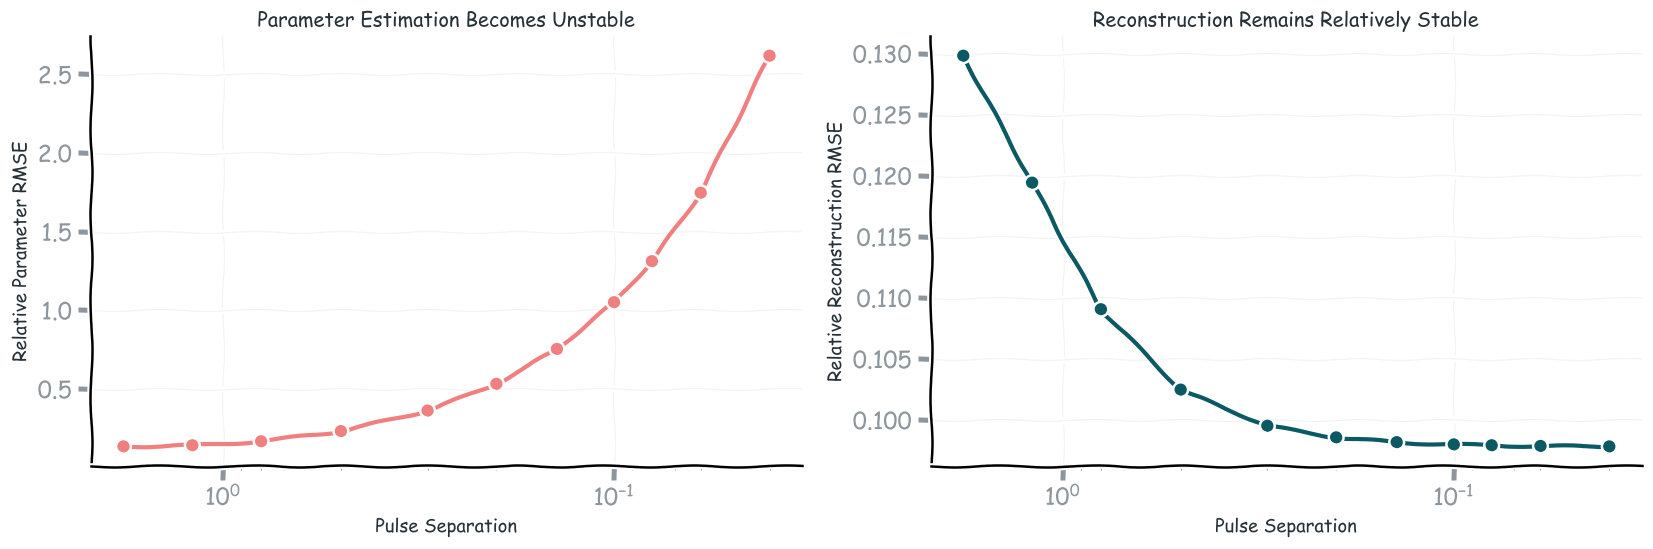

In [24]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.8)
)

# Parameter Estimation Error
ax = axes[0]

ax.plot(
    separation_values,
    parameter_rmse,
    color=RED,
    marker="o",
    markersize=6,
    linestyle="-",
    linewidth=2.5
)

ax.set_xlabel("Pulse Separation")
ax.set_ylabel("Relative Parameter RMSE")

ax.set_title(
    "Parameter Estimation Becomes Unstable"
)

ax.set_xscale("log")

ax.invert_xaxis()

ax.grid(
    True,
    which="major",
    alpha=0.15,
    linestyle="-",
    linewidth=0.7
)


# Signal Reconstruction Error

ax = axes[1]

ax.plot(
    separation_values,
    reconstruction_rmse,
    color=TEAL,
    marker="o",
    markersize=6,
    linestyle="-",
    linewidth=2.5
)

ax.set_xlabel("Pulse Separation")
ax.set_ylabel("Relative Reconstruction RMSE")

ax.set_title(
    "Reconstruction Remains Relatively Stable"
)

ax.set_xscale("log")

ax.invert_xaxis()

ax.grid(
    True,
    which="major",
    alpha=0.15,
    linestyle="-",
    linewidth=0.7
)

plt.tight_layout()
plt.show()

The simulation demonstrates that estimation reliability depends strongly on the similarity between the signal templates. When the pulses are well separated, their individual contributions are distinguishable.As the pulses become increasingly similar, many different amplitude combinations produce nearly the same combined waveform. Consequently, small perturbations caused by measurement noise can produce large changes in the estimated amplitudes.

*Why Does Reconstruction Remain Relatively Stable?*
The reconstructed signal is:

$$
\hat{\mathbf x} =
\hat a_1\mathbf s_1 +
\hat a_2\mathbf s_2
$$
When the templates are nearly identical, changes in the two estimated amplitudes may compensate for each other.
For example, an increase in $\hat a_1$ can be partially offset by a decrease in $\hat a_2$.
Therefore, the combined reconstructed waveform may remain almost unchanged.

### Optional: The Geometry of Ill-Conditioned Estimation

The ML estimator minimizes the squared reconstruction error:
$$
J(a_1,a_2) =
\|\mathbf y-a_1\mathbf s_1-a_2\mathbf s_2\|_2^2
$$
For two unknown amplitudes, we can visualize this objective as a function of $a_1$ and $a_2$.

**Separated Signals**

When the templates are sufficiently different, the objective has a well-defined, relatively localized minimum.
Changes in either amplitude noticeably affect the reconstructed waveform.

**Overlapping Signals**

When the templates become highly similar, the objective develops an elongated valley.
Moving along this valley changes the individual amplitudes substantially while producing only a small change in reconstruction error.

**Identical Signals**

When the templates are identical, the objective depends only on their sum:

$$
J(a_1,a_2) =
\|\mathbf y-(a_1+a_2)\mathbf s\|_2^2
$$
Consequently, the minimum occurs along an entire line of amplitude combinations satisfying:
$$
a_1+a_2=\hat c_{\mathrm{ML}}
$$
This explains geometrically why the individual amplitudes cannot be uniquely identified.

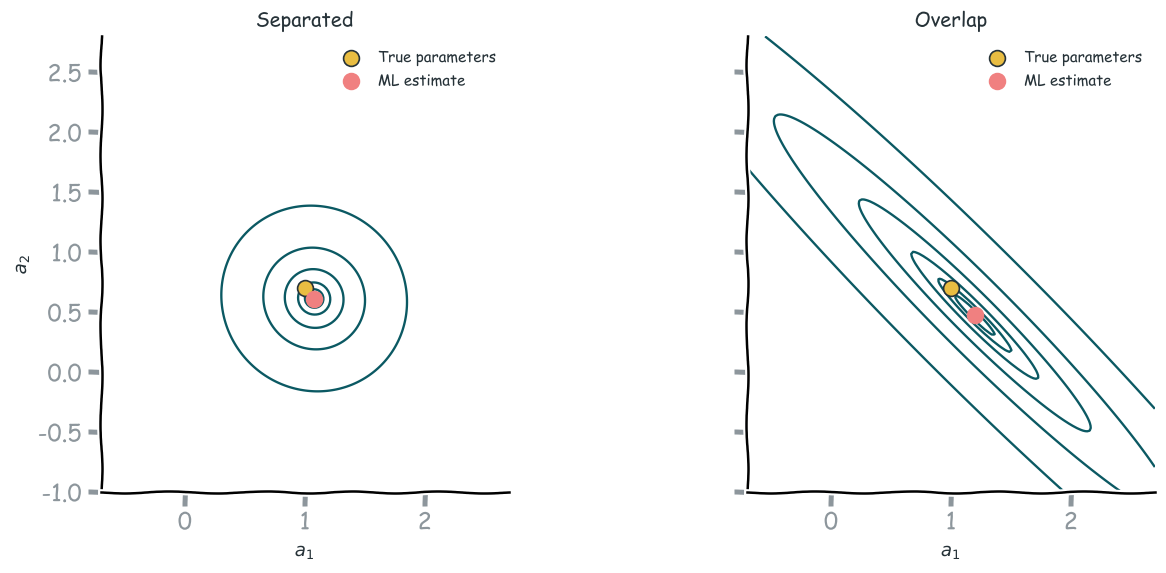

In [25]:
a1_values = np.linspace(-0.7, 2.7, 200)
a2_values = np.linspace(-1.0, 2.8, 200)

A1, A2 = np.meshgrid(
    a1_values,
    a2_values
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

selected_cases = [
    "Separated",
    "Overlap"
]

for ax, name in zip(axes, selected_cases):

    data = case_data[name]

    S = data["S"]
    y = data["y"]
    a_hat = data["a_hat"]

    # Least-squares objective: J(a) = ||y - S a||^2

    G = S.T @ S
    b = S.T @ y

    J = (
        np.dot(y, y)
        - 2 * b[0] * A1
        - 2 * b[1] * A2
        + G[0, 0] * A1**2
        + 2 * G[0, 1] * A1 * A2
        + G[1, 1] * A2**2
    )

    J_relative = np.maximum(
        J - np.min(J),
        0
    )

    levels = [0.03, 0.1, 0.3, 1.0, 3.0, 10.0]

    ax.contour(
        A1,
        A2,
        J_relative,
        levels=levels,
        colors=TEAL,
        linewidths=1.4
    )

    ax.scatter(
        a_true_pair[0],
        a_true_pair[1],
        color=YELLOW,
        s=90,
        edgecolor=DARK,
        zorder=5,
        label="True parameters"
    )

    ax.scatter(
        a_hat[0],
        a_hat[1],
        color=RED,
        s=90,
        zorder=5,
        label="ML estimate"
    )

    ax.set_title(name)

    ax.set_xlabel(r"$a_1$")

    ax.legend(
        frameon=False,
        fontsize=9
    )

axes[0].set_ylabel(r"$a_2$")

for ax in axes:
    ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

### Conclusion

**Good signal reconstruction does not necessarily imply reliable parameter estimation.**

In this experiment, the limitation is not caused by an incorrect optimization method. It arises because the observations provide insufficient information to distinguish the individual contributions of highly similar signals.
This is closely related to the concepts of:
- Identifiability.
- Ill-conditioning.
- Estimation variance.
- Fisher information.

# Part III: Bayesian Estimation

## Experiment 4: Maximum a Posteriori Estimation

### From Maximum Likelihood to Bayesian Estimation

In the previous experiments, we used Maximum Likelihood Estimation (MLE) to estimate unknown parameters from noisy observations. we saw that maximum likelihood uses the statistical model of the observed data. However, it does not directly incorporate prior information about the unknown parameter.

Suppose previous measurements or physical knowledge suggest that certain amplitude values are more plausible than others. Should we ignore that information?

***Bayesian estimation** provides a framework for incorporating prior knowledge into the estimation process.*


#### Bayes Rule

The posterior distribution is obtained using:
$$
\boxed{
p(a\mid\mathbf y) =
\frac{
p(\mathbf y\mid a)p(a)
}{
p(\mathbf y)
}
}
$$
where:
- $p(\mathbf y\mid a)$ is the likelihood.
- $p(a)$ is the prior distribution.
- $p(a\mid\mathbf y)$ is the posterior distribution.
- $p(\mathbf y)$ is the marginal likelihood, which normalizes the posterior.

Since $p(\mathbf y)$ does not depend on the candidate amplitude $a$:
$$
\boxed{
p(a\mid\mathbf y)
\propto
p(\mathbf y\mid a)p(a)
}
$$

#### Maximum a Posteriori Estimation

The MAP estimator selects the parameter value that maximizes the posterior distribution:
$$
\boxed{
\hat a_{\mathrm{MAP}} =
\arg\max_a p(a\mid\mathbf y)
}
$$

ML Versus MAP:

**Maximum Likelihood:**

Which parameter value best explains the observed data?

**Maximum a Posteriori:**

Which parameter value is most plausible after combining the observed data with prior information?


>Q: Suppose the likelihood favors an amplitude near $1.5$, but our prior information favors an amplitude near $0.75$. **Where do you expect the MAP estimate to be located?** Will it necessarily coincide with either the likelihood maximum or the prior maximum?

### Combining the Likelihood with a Gaussian Prior

We return to the Gaussian amplitude-estimation problem:
$$
\mathbf y=a\mathbf s+\mathbf w
$$
where:
$$
\mathbf w\sim\mathcal N(\mathbf 0,\sigma^2\mathbf I)
$$

1. **Step 1: Likelihood**

For a fixed observation, the likelihood is:
$$
p(\mathbf y\mid a)
\propto
\exp\left(
-\frac{
\|\mathbf y-a\mathbf s\|_2^2
}{
2\sigma^2
}
\right)
$$
As a function of the candidate amplitude, this likelihood has a Gaussian shape.Its maximum occurs at:
$$
\hat a_{\mathrm{ML}} =
\frac{\mathbf s^T\mathbf y}
{\mathbf s^T\mathbf s}
$$
The width of the likelihood is characterized by:
$$
\boxed{
\sigma_L^2 =
\frac{\sigma^2}{\mathbf s^T\mathbf s}
}
$$
Here, $\sigma_L^2$ describes the spread of the Gaussian-shaped likelihood as a function of $a$.

2. **Step 2: Prior Distribution**

Suppose our prior information about the amplitude is represented by a Gaussian distribution:
$$
\boxed{
a\sim\mathcal N(\mu_0,\tau^2)
}
$$
where:
- $\mu_0$ is the prior mean.
- $\tau^2$ is the prior variance.

The prior density is:
$$
p(a) =
\frac{1}{\sqrt{2\pi\tau^2}}
\exp\left(
-\frac{(a-\mu_0)^2}{2\tau^2}
\right)
$$
A smaller prior variance indicates greater confidence in values near $\mu_0$.
A larger prior variance represents greater prior uncertainty.

3. **Step 3: Posterior Distribution**

Using Bayes' rule:
$$
p(a\mid\mathbf y)
\propto
p(\mathbf y\mid a)p(a)
$$
Because both the likelihood and prior have Gaussian forms, the posterior is also Gaussian:
$$
\boxed{
p(a\mid\mathbf y) =
\mathcal N(\mu_{\mathrm{post}},\sigma_{\mathrm{post}}^2)
}
$$
Its variance is:
$$
\boxed{
\sigma_{\mathrm{post}}^2 =
\left(
\frac{\mathbf s^T\mathbf s}{\sigma^2} +
\frac{1}{\tau^2}
\right)^{-1}
}
$$
Its mean is:
$$
\boxed{
\mu_{\mathrm{post}} =
\sigma_{\mathrm{post}}^2
\left(
\frac{\mathbf s^T\mathbf y}{\sigma^2} +
\frac{\mu_0}{\tau^2}
\right)
}
$$

4. **Step 4: MAP Estimate**

The MAP estimate corresponds to the posterior mode. Since our posterior is Gaussian, its mode equals its mean:
$$
\boxed{
\hat a_{\mathrm{MAP}} =
\mu_{\mathrm{post}}
}
$$
Therefore:
$$
\boxed{
\hat a_{\mathrm{MAP}} =
\frac{
\frac{\mathbf s^T\mathbf y}{\sigma^2} +
\frac{\mu_0}{\tau^2}
}{
\frac{\mathbf s^T\mathbf s}{\sigma^2} +
\frac{1}{\tau^2}
}
}
$$

The MAP estimate combines information from:
1. The observed data.
2. The prior distribution.  
The relative influence of these sources depends on their precision. A distribution with smaller variance has greater precision and therefore carries more weight in this Gaussian model.

In [26]:
s_map = np.asarray(s, dtype=float).copy()
y_map = np.asarray(y1, dtype=float).copy()

a_true_map = float(a_true)
sigma_map = float(sigma_true)

# Gaussian prior parameters
prior_mean = 0.75
prior_std = 0.18

# Gaussian Bayesian amplitude estimation
def gaussian_map_posterior(
    y,
    s,
    sigma,
    prior_mean,
    prior_std
):

    if sigma <= 0 or prior_std <= 0:
        raise ValueError(
            "Standard deviations must be positive."
        )

    signal_energy = np.dot(s, s)

    a_ml = np.dot(s, y) / signal_energy

    likelihood_var = sigma**2 / signal_energy

    posterior_var = 1 / (
        1 / likelihood_var
        + 1 / prior_std**2
    )

    posterior_mean = posterior_var * (
        a_ml / likelihood_var
        + prior_mean / prior_std**2
    )

    data_weight = posterior_var / likelihood_var

    return {
        "a_ml": a_ml,
        "a_map": posterior_mean,
        "likelihood_std": np.sqrt(likelihood_var),
        "posterior_std": np.sqrt(posterior_var),
        "posterior_var": posterior_var,
        "data_weight": data_weight
    }

# Calculate posterior
result_map = gaussian_map_posterior(
    y=y_map,
    s=s_map,
    sigma=sigma_map,
    prior_mean=prior_mean,
    prior_std=prior_std
)

a_ml_map = result_map["a_ml"]
a_map = result_map["a_map"]

print("Gaussian Bayesian Amplitude Estimation")
print("-" * 48)

print(f"True amplitude:       {a_true_map:.4f}")
print(f"ML estimate:          {a_ml_map:.4f}")

print()
print(f"Prior mean:           {prior_mean:.4f}")
print(f"Prior std:            {prior_std:.4f}")

print()
print(f"MAP estimate:         {a_map:.4f}")
print(
    f"Posterior std:        "
    f"{result_map['posterior_std']:.4f}"
)

print()
print(
    f"Weight assigned to data: "
    f"{result_map['data_weight']:.2%}"
)

Gaussian Bayesian Amplitude Estimation
------------------------------------------------
True amplitude:       1.5000
ML estimate:          1.4726

Prior mean:           0.7500
Prior std:            0.1800

MAP estimate:         1.2569
Posterior std:        0.0983

Weight assigned to data: 70.15%


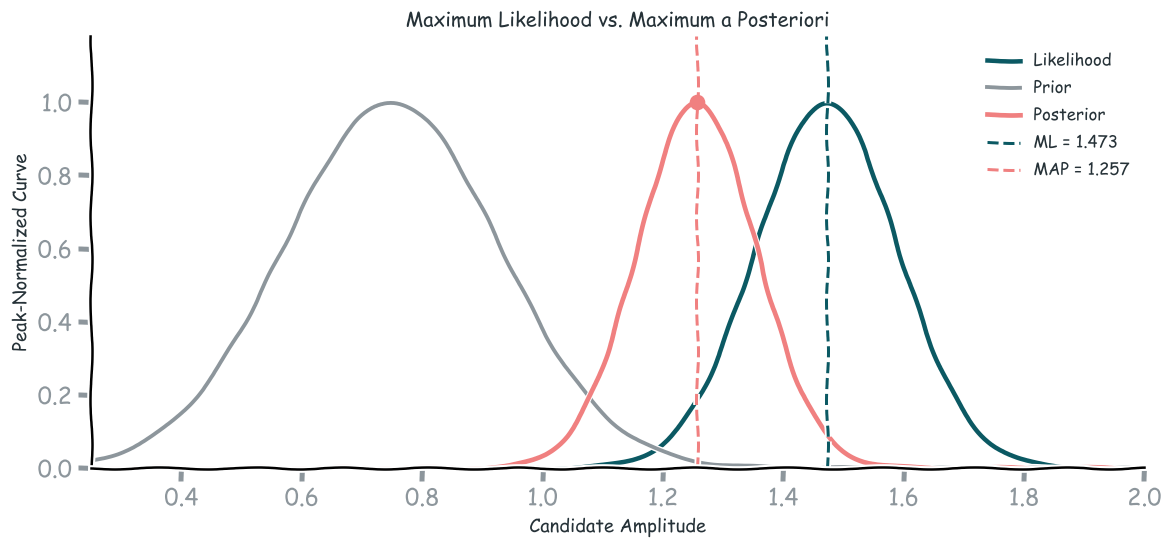

In [27]:
# Visualizing Likelihood, Prior, and Posterior
a_grid = np.linspace(
    0.25,
    2.0,
    1000
)

# Gaussian curve with unit peak height
def gaussian_shape(a, mean, std):
    return np.exp(
        -0.5 * ((a - mean) / std)**2
    )


# Likelihood, prior, and posterior shapes
likelihood_curve = gaussian_shape(
    a_grid,
    a_ml_map,
    result_map["likelihood_std"]
)

prior_curve = gaussian_shape(
    a_grid,
    prior_mean,
    prior_std
)

posterior_curve = gaussian_shape(
    a_grid,
    a_map,
    result_map["posterior_std"]
)

# Visualization
fig, ax = plt.subplots(figsize=(10, 4.8))

# Likelihood
ax.plot(
    a_grid,
    likelihood_curve,
    color=TEAL,
    linewidth=2.7,
    label="Likelihood"
)

# Prior
ax.plot(
    a_grid,
    prior_curve,
    color=GRAY,
    linewidth=2.3,
    label="Prior"
)

# Posterior
ax.plot(
    a_grid,
    posterior_curve,
    color=RED,
    linewidth=2.8,
    label="Posterior"
)

# ML estimate
ax.axvline(
    a_ml_map,
    color=TEAL,
    linestyle="--",
    linewidth=1.8,
    label=rf"ML = {a_ml_map:.3f}"
)

# MAP estimate
ax.axvline(
    a_map,
    color=RED,
    linestyle="--",
    linewidth=1.8,
    label=rf"MAP = {a_map:.3f}"
)

# Highlight posterior maximum
ax.scatter(
    a_map,
    1,
    color=RED,
    s=70,
    zorder=5
)

# Formatting
ax.set_xlabel("Candidate Amplitude")
ax.set_ylabel("Peak-Normalized Curve")

ax.set_title(
    "Maximum Likelihood vs. Maximum a Posteriori"
)

ax.set_xlim(a_grid[0], a_grid[-1])
ax.set_ylim(0, 1.18)

ax.legend(
    frameon=False,
    fontsize=10
)

plt.tight_layout()

fig.savefig(
    "MLSP_Week1_Experiment4_Gaussian_MAP.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

The likelihood represents the information provided by the observed signal under our assumed noise model. The prior represents our beliefs about plausible amplitude values before incorporating the current observation. The posterior combines these sources of information.

The ML estimator selects the maximum of the likelihood:
$$
\hat a_{\mathrm{ML}} =
\arg\max_a p(\mathbf y\mid a)
$$
The MAP estimator selects the maximum of the posterior:
$$
\hat a_{\mathrm{MAP}} =
\arg\max_a p(a\mid\mathbf y)
$$
In our example, the ML estimate is approximately:
$$
\hat a_{\mathrm{ML}}\approx1.473
$$
The prior mean is:
$$
\mu_0=0.75
$$
After incorporating the prior, the MAP estimate becomes approximately:
$$
\hat a_{\mathrm{MAP}}\approx1.257
$$
The MAP estimate shifts toward values favored by the prior.

In this simulation, the true amplitude is:
$$
a_{\mathrm{true}}=1.5
$$
The ML estimate happens to be closer to the true amplitude than the MAP estimate.

**Prior information can influence an estimate in a useful or misleading direction, depending on how well the prior represents the unknown parameter.**

### Prior Influence

For our Gaussian model, the MAP estimator can be written as:
$$
\hat a_{\mathrm{MAP}} =
\frac{
\frac{\hat a_{\mathrm{ML}}}{\sigma_L^2} +
\frac{\mu_0}{\tau^2}
}{
\frac{1}{\sigma_L^2} +
\frac{1}{\tau^2}
}
$$
where:
$$
\sigma_L^2 =
\frac{\sigma^2}{\mathbf s^T\mathbf s}
$$
Rearranging the expression gives:
$$
\boxed{
\hat a_{\mathrm{MAP}} =
\alpha\hat a_{\mathrm{ML}} +
(1-\alpha)\mu_0
}
$$
where:
$$
\boxed{
\alpha =
\frac{\tau^2}{\tau^2+\sigma_L^2}
}
$$
Equivalently:
$$
\alpha =
\frac{
\tau^2\mathbf s^T\mathbf s
}{
\tau^2\mathbf s^T\mathbf s+\sigma^2
}
$$
Since both variances are positive:
$$
0<\alpha<1
$$

The MAP estimator is a weighted combination of:

- The ML estimate, which represents the information from the current observation.
- The prior mean, which represents prior information.

The weighting depends on the relative uncertainty of the two sources.

**Case 1: Highly Informative Measurements**

When the likelihood is much more concentrated than the prior:
$$
\sigma_L^2\ll\tau^2
$$
we obtain:
$$
\alpha\approx1
$$
Therefore:
$$
\hat a_{\mathrm{MAP}}
\approx
\hat a_{\mathrm{ML}}
$$
The data have greater influence.

**Case 2: Highly Informative Prior**

When the prior is much more concentrated than the likelihood:
$$
\tau^2\ll\sigma_L^2
$$
we obtain:
$$
\alpha\approx0
$$
Therefore:
$$
\hat a_{\mathrm{MAP}}
\approx\mu_0
$$
The prior has greater influence.


> *Q: Suppose we keep the observed signal fixed but increase the noise standard deviation assumed by the likelihood model. **What happens to the MAP estimate?** Will it move toward the ML estimate or toward the prior mean?*

Assumed sigma    MAP estimate     Data weight    
-------------------------------------------------
0.240            1.4031           90.38%         
0.320            1.3577           84.10%         
0.480            1.2569           70.15%         
0.720            1.1192           51.09%         
0.960            1.0174           37.01%         
1.600            0.8762           17.46%         


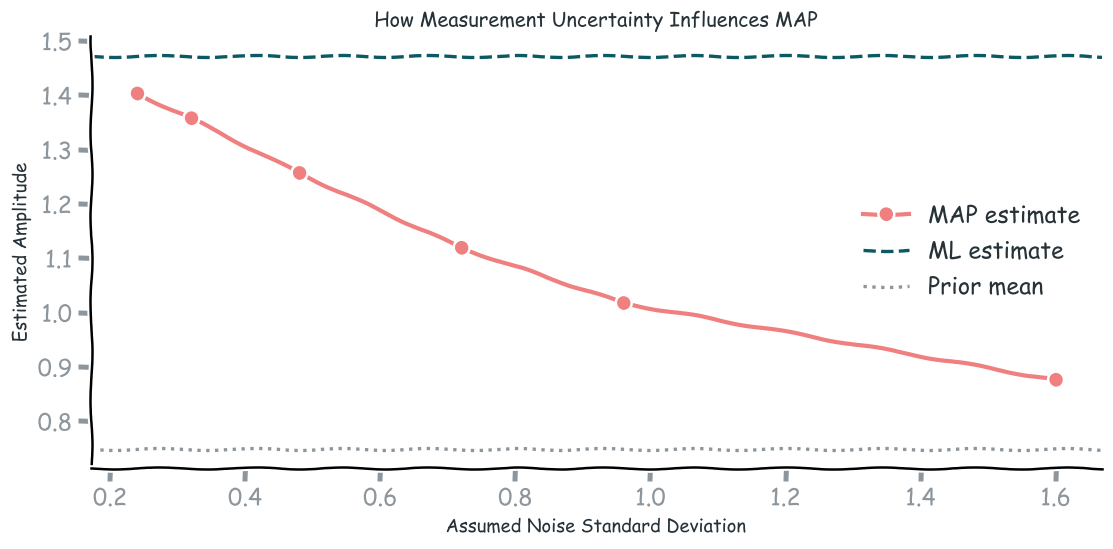

In [28]:
# Different assumed noise standard deviations
sigma_assumed_values = np.array([
    0.24,
    0.32,
    0.48,
    0.72,
    0.96,
    1.60
])

map_noise_values = []
data_weights = []

# Recompute the posterior for each assumed noise level
for sigma_assumed in sigma_assumed_values:

    result = gaussian_map_posterior(
        y=y_map,
        s=s_map,
        sigma=sigma_assumed,
        prior_mean=prior_mean,
        prior_std=prior_std
    )

    map_noise_values.append(
        result["a_map"]
    )

    data_weights.append(
        result["data_weight"]
    )

map_noise_values = np.array(map_noise_values)
data_weights = np.array(data_weights)

# results
print(
    f"{'Assumed sigma':<17}"
    f"{'MAP estimate':<17}"
    f"{'Data weight':<15}"
)

print("-" * 49)

for i in range(len(sigma_assumed_values)):

    print(
        f"{sigma_assumed_values[i]:<17.3f}"
        f"{map_noise_values[i]:<17.4f}"
        f"{data_weights[i]:<15.2%}"
    )

# Visualization
fig, ax = plt.subplots(figsize=(9.5, 4.8))

# MAP estimates
ax.plot(
    sigma_assumed_values,
    map_noise_values,
    color=RED,
    marker="o",
    markersize=7,
    linewidth=2.5,
    label="MAP estimate"
)

# ML estimate 
ax.axhline(
    a_ml_map,
    color=TEAL,
    linestyle="--",
    linewidth=2,
    label="ML estimate"
)

# Prior mean
ax.axhline(
    prior_mean,
    color=GRAY,
    linestyle=":",
    linewidth=2,
    label="Prior mean"
)

ax.set_xlabel("Assumed Noise Standard Deviation")
ax.set_ylabel("Estimated Amplitude")

ax.set_title(
    "How Measurement Uncertainty Influences MAP"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

Here, we kept the observed signal unchanged, and only modified the assumed noise standard deviation.  
**Maximum Likelihood**  
For our model:

$$
\hat a_{\mathrm{ML}} =
\frac{\mathbf s^T\mathbf y}{\mathbf s^T\mathbf s}
$$
The ML estimate does not depend on the assumed common noise variance. Therefore, its value remains unchanged.

**Maximum a Posteriori**  
The MAP estimator is:
$$
\hat a_{\mathrm{MAP}} =
\alpha\hat a_{\mathrm{ML}} +
(1-\alpha)\mu_0
$$
where:
$$
\alpha =
\frac{
\tau^2\mathbf s^T\mathbf s
}{
\tau^2\mathbf s^T\mathbf s+\sigma^2
}
$$
As the assumed measurement noise variance increases, $\alpha$ decreases. The posterior assigns less relative weight to the current observation and more weight to the prior. Consequently, the MAP estimate moves toward the prior mean.


> When the prior is sufficiently informative relative to the noisy measurements, the prior has greater influence on the MAP estimate.

### Effect of Prior Strength on the MAP Estimate?

Our Gaussian prior is:
$$
a\sim\mathcal N(\mu_0,\tau^2)
$$
The prior mean $\mu_0$ represents the center of our prior information. The prior variance $\tau^2$ determines how strongly the prior distribution is concentrated around that value.

**Strong Prior**  
A small prior variance produces a narrow prior distribution. This represents stronger confidence in values close to the prior mean.

**Weak Prior**  
A large prior variance produces a broad prior distribution.
This represents weaker prior concentration around the prior mean.

> **Q:** Suppose we keep the observed signal and noise model fixed.We gradually increase the prior standard deviation. **What happens to the MAP estimate?** Will it move toward the prior mean or toward the ML estimate?

Limiting Behavior:

As the prior variance becomes very large:
$$
\tau^2\rightarrow\infty
$$
the prior becomes increasingly diffuse over the region supported by the likelihood.
In this limit:
$$
\boxed{
\hat a_{\mathrm{MAP}}
\rightarrow
\hat a_{\mathrm{ML}}
}
$$

Prior std      MAP estimate   
------------------------------
0.070          0.9395         
0.120          1.1192         
0.180          1.2569         
0.350          1.3995         
0.650          1.4498         
1.000          1.4628         


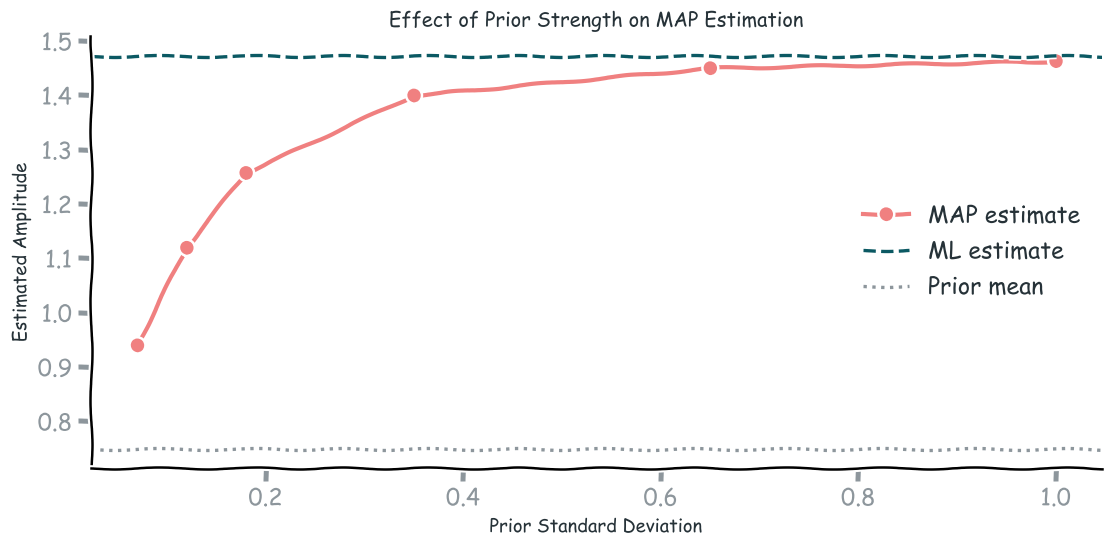

In [29]:
# Effect of Prior Strength on MAP

prior_std_values = np.array([
    0.07,
    0.12,
    0.18,
    0.35,
    0.65,
    1.00
])

map_prior_values = []

# Compute MAP estimates
for tau in prior_std_values:

    result = gaussian_map_posterior(
        y=y_map,
        s=s_map,
        sigma=sigma_map,
        prior_mean=prior_mean,
        prior_std=tau
    )

    map_prior_values.append(
        result["a_map"]
    )

map_prior_values = np.array(map_prior_values)

# Display  results
print(
    f"{'Prior std':<15}"
    f"{'MAP estimate':<15}"
)

print("-" * 30)

for tau, estimate in zip(
    prior_std_values,
    map_prior_values
):

    print(
        f"{tau:<15.3f}"
        f"{estimate:<15.4f}"
    )

# Visualization
fig, ax = plt.subplots(figsize=(9.5, 4.8))

ax.plot(
    prior_std_values,
    map_prior_values,
    color=RED,
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="MAP estimate"
)

# ML reference
ax.axhline(
    a_ml_map,
    color=TEAL,
    linestyle="--",
    linewidth=2,
    label="ML estimate"
)

# Prior mean
ax.axhline(
    prior_mean,
    color=GRAY,
    linestyle=":",
    linewidth=2,
    label="Prior mean"
)

ax.set_xlabel("Prior Standard Deviation")
ax.set_ylabel("Estimated Amplitude")

ax.set_title(
    "Effect of Prior Strength on MAP Estimation"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

The MAP estimate depends on both the prior mean and the prior variance. A narrow prior assigns relatively high probability density to a smaller range of parameter values. So the posterior is more strongly influenced by the prior. A broad prior allows the observations to have greater relative influence.

Relationship Between ML and MAP:

For the Gaussian model:
$$
\hat a_{\mathrm{MAP}} =
\alpha\hat a_{\mathrm{ML}} +
(1-\alpha)\mu_0
$$
As the prior variance increases:
$$
\alpha\rightarrow1
$$
Therefore:
$$
\hat a_{\mathrm{MAP}}
\rightarrow
\hat a_{\mathrm{ML}}
$$

**Note:**
> **MAP does not automatically ignore the observed data or force the estimate toward the prior.**  
> The influence of each information source depends on its relative precision.  
> An informative prior can meaningfully change the estimate.  
> A sufficiently diffuse prior makes MAP approach ML in this Gaussian model.

### MAP and Regularization

In Experiment 3, we considered the observation model:
$$
\mathbf y=\mathbf S\mathbf a+\mathbf w
$$
where:
$$
\mathbf a=
\begin{bmatrix}
a_1\\
a_2
\end{bmatrix}
$$
contains the unknown amplitudes of two signal components. Under additive white Gaussian noise, the ML estimator solves:
$$
\boxed{
\hat{\mathbf a}_{\mathrm{ML}} =
\arg\min_{\mathbf a}
\|\mathbf y-\mathbf S\mathbf a\|_2^2
}
$$
We found that ML estimates can become highly unstable when the columns of $\mathbf S$ are nearly linearly dependent.

**Introducing Prior Information**

Suppose we have prior information suggesting that the amplitudes are likely to be near a particular vector:
$$
\boldsymbol\mu_0=
\begin{bmatrix}
\mu_1\\
\mu_2
\end{bmatrix}
$$
We introduce an isotropic Gaussian prior:
$$
\boxed{
\mathbf a
\sim
\mathcal N(
\boldsymbol\mu_0,
\tau^2\mathbf I
)
}
$$
This prior favors amplitude combinations near $\boldsymbol\mu_0$.

**Maximum a Posteriori Estimation**\

Using Bayes' rule:
$$
p(\mathbf a\mid\mathbf y)
\propto
p(\mathbf y\mid\mathbf a)p(\mathbf a)
$$
Taking the negative logarithm and removing terms that do not depend on $\mathbf a$ gives:
$$
\boxed{
\hat{\mathbf a}_{\mathrm{MAP}} =
\arg\min_{\mathbf a}
\left[
\frac{1}{2\sigma^2}
\|\mathbf y-\mathbf S\mathbf a\|_2^2 +
\frac{1}{2\tau^2}
\|\mathbf a-\boldsymbol\mu_0\|_2^2
\right]
}
$$
The objective contains two terms.

**Data-fitting term:**
$$
\|\mathbf y-\mathbf S\mathbf a\|_2^2
$$
This encourages the estimated amplitudes to explain the observed signal.
**Regularization term:**
$$
\|\mathbf a-\boldsymbol\mu_0\|_2^2
$$
This encourages the amplitudes to remain near values favored by the prior.

**Regularized Least Squares**

Multiplying the objective by $2\sigma^2$ gives the equivalent optimization problem:
$$
\boxed{
\hat{\mathbf a}_{\mathrm{MAP}} =
\arg\min_{\mathbf a}
\left[
\|\mathbf y-\mathbf S\mathbf a\|_2^2 +
\lambda
\|\mathbf a-\boldsymbol\mu_0\|_2^2
\right]
}
$$
where:
$$
\boxed{
\lambda=\frac{\sigma^2}{\tau^2}
}
$$
The parameter $\lambda$ controls the influence of regularization.
For a Gaussian likelihood and Gaussian prior, MAP estimation is therefore equivalent to a form of regularized least squares.

**Closed-Form Solution**

The MAP estimator is:
$$
\boxed{
\hat{\mathbf a}_{\mathrm{MAP}} =
\left(
\mathbf S^T\mathbf S+\lambda\mathbf I
\right)^{-1}
\left(
\mathbf S^T\mathbf y+\lambda\boldsymbol\mu_0
\right)
}
$$
Unlike ordinary least squares, this expression remains well-defined even when $\mathbf S^T\mathbf S$ is singular, provided $\lambda>0$.

> **Q:** In Experiment 3, the amplitudes became unstable because the two signal templates were highly similar. **What do you expect to happen if we introduce a reasonable Gaussian prior?** Will the MAP estimates become more stable? Will the reconstructed waveform necessarily become more accurate?


In [30]:
# MAP Estimation for Two Overlapping Signals

overlap_data = case_data["Overlap"]

S_overlap = overlap_data["S"]
y_overlap = overlap_data["y"]
x_overlap = overlap_data["x"]

a_true_overlap = a_true_pair.copy()

# Prior parameters
prior_mean_pair = np.array([0.8, 0.8])
prior_std_pair = 0.35

sigma_pair = sigma_overlap

# ML estimation
a_ml_pair = np.linalg.lstsq(
    S_overlap,
    y_overlap,
    rcond=None
)[0]

# MAP estimation
lambda_map = sigma_pair**2 / prior_std_pair**2

A = (
    S_overlap.T @ S_overlap
    + lambda_map * np.eye(2)
)

# Right-hand side
b = (
    S_overlap.T @ y_overlap
    + lambda_map * prior_mean_pair
)

# Solve the regularized system
a_map_pair = np.linalg.solve(A, b)

# Reconstructions
x_ml_pair = S_overlap @ a_ml_pair
x_map_pair = S_overlap @ a_map_pair

# Parameter errors
ml_parameter_error = np.linalg.norm(
    a_ml_pair - a_true_overlap
)

map_parameter_error = np.linalg.norm(
    a_map_pair - a_true_overlap
)

# Relative clean-signal reconstruction errors
ml_reconstruction_error = (
    np.linalg.norm(x_ml_pair - x_overlap)
    / np.linalg.norm(x_overlap)
)

map_reconstruction_error = (
    np.linalg.norm(x_map_pair - x_overlap)
    / np.linalg.norm(x_overlap)
)

# Display results
print("ML vs. MAP — Strongly Overlapping Pulses")
print("-" * 55)

print("True amplitudes:", a_true_overlap)

print(
    "ML estimates:   ",
    np.round(a_ml_pair, 4)
)

print(
    "MAP estimates:  ",
    np.round(a_map_pair, 4)
)

print()
print(f"ML parameter error:  {ml_parameter_error:.4f}")
print(f"MAP parameter error: {map_parameter_error:.4f}")

print()
print(
    f"ML reconstruction error:  "
    f"{100 * ml_reconstruction_error:.2f}%"
)

print(
    f"MAP reconstruction error: "
    f"{100 * map_reconstruction_error:.2f}%"
)

print()
print(f"Regularization parameter: {lambda_map:.4f}")

ML vs. MAP — Strongly Overlapping Pulses
-------------------------------------------------------
True amplitudes: [1.  0.7]
ML estimates:    [1.1984 0.4742]
MAP estimates:   [0.9155 0.7532]

ML parameter error:  0.3006
MAP parameter error: 0.0998

ML reconstruction error:  3.59%
MAP reconstruction error: 2.12%

Regularization parameter: 1.8808


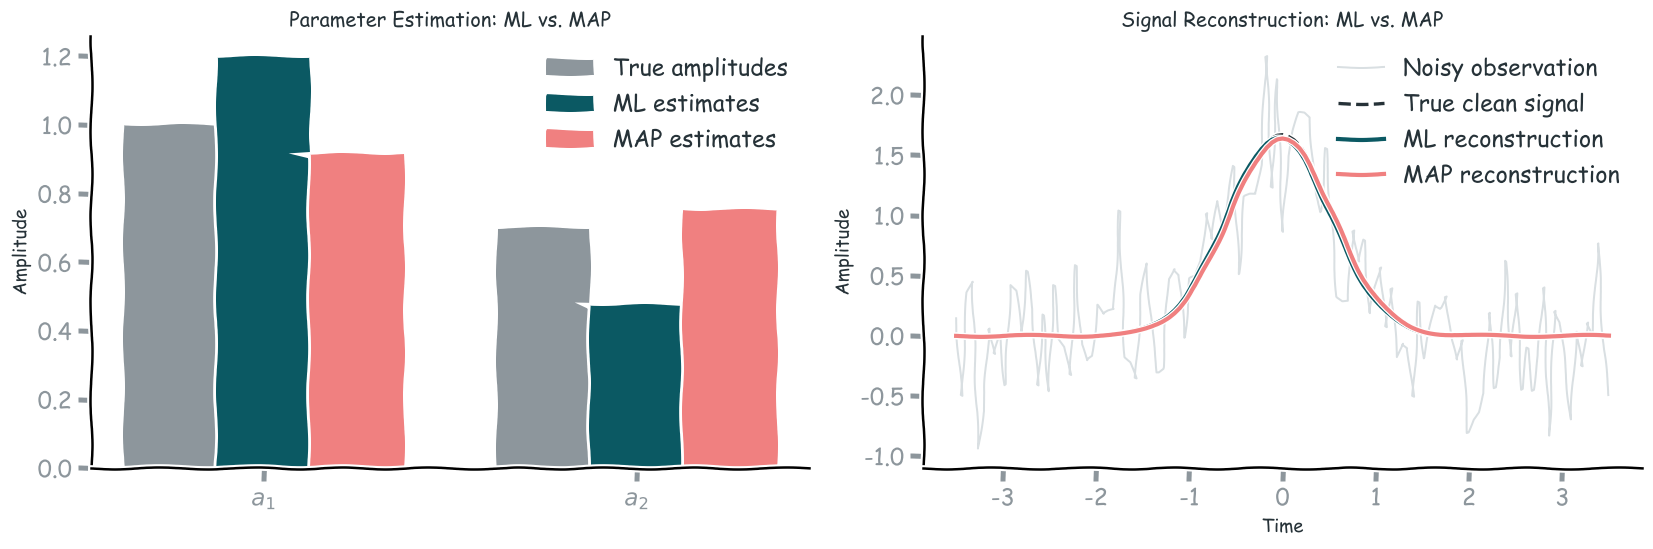

In [31]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.8)
)

#  Parameter Estimates
ax = axes[0]

positions = np.arange(2)

bar_width = 0.25

# True amplitudes
ax.bar(
    positions - bar_width,
    a_true_overlap,
    width=bar_width,
    color=GRAY,
    label="True amplitudes"
)

# ML estimates
ax.bar(
    positions,
    a_ml_pair,
    width=bar_width,
    color=TEAL,
    label="ML estimates"
)

# MAP estimates
ax.bar(
    positions + bar_width,
    a_map_pair,
    width=bar_width,
    color=RED,
    label="MAP estimates"
)

ax.set_xticks(positions)

ax.set_xticklabels([
    r"$a_1$",
    r"$a_2$"
])

ax.set_ylabel("Amplitude")

ax.set_title(
    "Parameter Estimation: ML vs. MAP"
)

ax.legend(frameon=False)

# Signal Reconstruction
ax = axes[1]

# Noisy observation
ax.plot(
    t,
    y_overlap,
    color=LIGHT_GRAY,
    linewidth=1.2,
    label="Noisy observation"
)

# True clean signal
ax.plot(
    t,
    x_overlap,
    color=DARK,
    linestyle="--",
    linewidth=2,
    label="True clean signal"
)

# ML reconstruction
ax.plot(
    t,
    x_ml_pair,
    color=TEAL,
    linewidth=2.5,
    label="ML reconstruction"
)

# MAP reconstruction
ax.plot(
    t,
    x_map_pair,
    color=RED,
    linewidth=2.5,
    label="MAP reconstruction"
)

ax.set_xlabel("Time")
ax.set_ylabel("Amplitude")

ax.set_title(
    "Signal Reconstruction: ML vs. MAP"
)

ax.legend(frameon=False)

plt.tight_layout()

fig.savefig(
    "MLSP_Week1_Experiment4_MAP_Regularization.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

MAP introduced an additional preference for amplitude combinations near the prior mean:
$$
\boldsymbol\mu_0=
\begin{bmatrix}
0.8\\
0.8
\end{bmatrix}
$$
The MAP estimator balanced two objectives:
$$
\boxed{
\text{Data Fit} +
\text{Prior Regularization}
}
$$
More precisely:
$$
\hat{\mathbf a}_{\mathrm{MAP}} =
\arg\min_{\mathbf a}
\left[
\|\mathbf y-\mathbf S\mathbf a\|_2^2 +
\lambda
\|\mathbf a-\boldsymbol\mu_0\|_2^2
\right]
$$
The regularization term discourages solutions that deviate strongly from the prior mean.This can reduce the sensitivity of the estimated amplitudes to measurement noise.

However, MAP does not always improve the estimation, it estimates depend on the prior assumptions. If the prior favors parameter values that are inconsistent with the true parameters, it can introduce substantial estimation bias. Therefore, improved numerical stability does not automatically imply improved estimation accuracy.

**Identical signals case:**

When:
$$
\mathbf s_1=\mathbf s_2
$$
the observations depend only on:
$$
a_1+a_2
$$
A proper Gaussian prior can still produce a unique MAP estimate. However, this does not mean the individual amplitudes have become identifiable from the observations.The unique result is obtained by combining the incomplete measurement information with assumptions encoded in the prior.

### Conclusion

**Maximum likelihood relies on the observed data, while MAP combines the observed data with prior information.**
The result depends on the relative uncertainty of these information sources.

# Part IV: MMSE

Suppose we have calculated the posterior distribution and must choose a single estimate, denoted by $\tilde a$.
Different estimates may have different consequences depending on how we measure estimation error.
For example, consider squared-error loss:
$$
\boxed{
L(a,\tilde a) =
(a-\tilde a)^2
}
$$
This loss penalizes large estimation errors more strongly than small errors.
Since the unknown parameter is uncertain under the posterior distribution, we cannot directly calculate its squared error before knowing its true value.
Instead, we calculate the **posterior expected squared error**:
$$
\boxed{
R(\tilde a\mid\mathbf y) =
\mathbb E
\left[
(a-\tilde a)^2
\mid\mathbf y
\right]
}
$$
Equivalently:
$$
R(\tilde a\mid\mathbf y) =
\int
(a-\tilde a)^2
p(a\mid\mathbf y)\,da
$$

## Experiment 5: Minimum Mean Squared Error Estimation

The MMSE estimator selects the estimate that minimizes this posterior expected squared error:
$$
\boxed{
\hat a_{\mathrm{MMSE}} =
\arg\min_{\tilde a}
R(\tilde a\mid\mathbf y)
}
$$
For squared-error loss, the solution is the posterior mean: 
$$
\boxed{
\hat a_{\mathrm{MMSE}} =
\mathbb E[a\mid\mathbf y]
}
$$
For a continuous parameter:
$$
\boxed{
\hat a_{\mathrm{MMSE}} =
\int a\,p(a\mid\mathbf y)\,da
}
$$

MAP Versus MMSE:  
**MAP** selects the maximum of the posterior density.  
**MMSE** selects the mean of the posterior distribution.

These are different estimation criteria.

The posterior mean and mode may coincide for some distributions, but they are not generally equal.

> **Q: If a posterior distribution is asymmetric, do you expect its mean and mode to be located at the same parameter value?**


### Gaussian Posterior: When MAP Equals MMSE

In Experiment 4, we considered the observation model:
$$
\mathbf y=a\mathbf s+\mathbf w
$$
with Gaussian measurement noise:
$$
\mathbf w\sim\mathcal N(\mathbf 0,\sigma^2\mathbf I)
$$
We also introduced a Gaussian prior:
$$
a\sim\mathcal N(\mu_0,\tau^2)
$$
The resulting posterior was Gaussian:
$$
\boxed{
p(a\mid\mathbf y) =
\mathcal N(
\mu_{\mathrm{post}},
\sigma_{\mathrm{post}}^2
)
}
$$
For a Gaussian distribution, the mean and mode coincide.
Therefore, the MAP estimator is:
$$
\hat a_{\mathrm{MAP}} =
\mu_{\mathrm{post}}
$$
The MMSE estimator is:
$$
\hat a_{\mathrm{MMSE}} =
\mathbb E[a\mid\mathbf y] =
\mu_{\mathrm{post}}
$$
Consequently:
$$
\boxed{
\hat a_{\mathrm{MAP}} =
\hat a_{\mathrm{MMSE}}
}
$$


MAP and MMSE produce the same numerical result for a Gaussian posterior.
However, they arrive at that result through different estimation criteria:
- MAP maximizes posterior density.
- MMSE minimizes posterior expected squared error.

Their equality is a consequence of the posterior distribution's shape, not a general property of Bayesian estimation.


Gaussian Posterior
---------------------------------------------
MAP estimate:  1.256908
MMSE estimate: 1.256908

Are MAP and MMSE equal? True


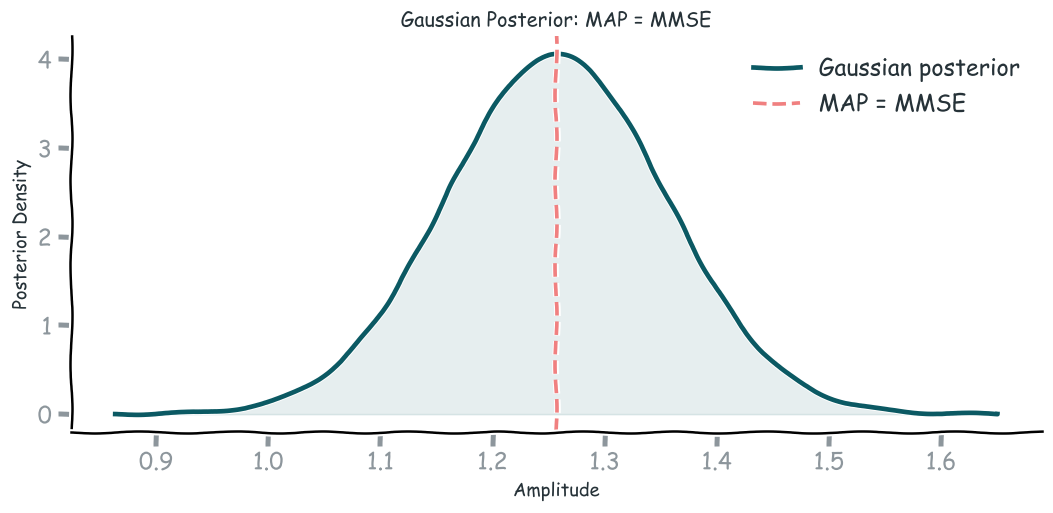

In [32]:
plt.rcParams["grid.linewidth"] = 0.7

# (from experiment 4)
gaussian_result_5 = gaussian_map_posterior(
    y=y_map,
    s=s_map,
    sigma=sigma_map,
    prior_mean=prior_mean,
    prior_std=prior_std
)

# Gaussian posterior parameters
posterior_mean_gaussian = gaussian_result_5["a_map"]
posterior_std_gaussian = gaussian_result_5["posterior_std"]

# MAP = mode of Gaussian posterior
a_map_gaussian = posterior_mean_gaussian

# MMSE = mean of Gaussian posterior
a_mmse_gaussian = posterior_mean_gaussian

#  results
print("Gaussian Posterior")
print("-" * 45)

print(f"MAP estimate:  {a_map_gaussian:.6f}")
print(f"MMSE estimate: {a_mmse_gaussian:.6f}")

print()
print(
    "Are MAP and MMSE equal?",
    np.isclose(a_map_gaussian, a_mmse_gaussian)
)

# Plot Gaussian posterior
a_grid_gaussian = np.linspace(
    posterior_mean_gaussian - 4 * posterior_std_gaussian,
    posterior_mean_gaussian + 4 * posterior_std_gaussian,
    600
)

posterior_pdf_gaussian = norm.pdf(
    a_grid_gaussian,
    loc=posterior_mean_gaussian,
    scale=posterior_std_gaussian
)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    a_grid_gaussian,
    posterior_pdf_gaussian,
    color=TEAL,
    linewidth=2.8,
    label="Gaussian posterior"
)

ax.fill_between(
    a_grid_gaussian,
    posterior_pdf_gaussian,
    color=TEAL,
    alpha=0.10
)

# MAP and MMSE coincide
ax.axvline(
    a_map_gaussian,
    color=RED,
    linestyle="--",
    linewidth=2.2,
    label="MAP = MMSE"
)

ax.set_xlabel("Amplitude")
ax.set_ylabel("Posterior Density")

ax.set_title(
    "Gaussian Posterior: MAP = MMSE"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### An Asymmetric Posterior

We return to the familiar signal model:
$$
\mathbf y=a\mathbf s+\mathbf w
$$
where:
$$
\mathbf w\sim\mathcal N(\mathbf 0,\sigma^2\mathbf I)
$$
However, suppose the unknown amplitude represents a nonnegative signal strength.
Therefore:
$$
\boxed{
a\geq0
}
$$
We also assume that smaller amplitudes are more likely before observing the current measurement.  
A possible prior is the exponential distribution:
$$
\boxed{
p(a) =
\begin{cases}
\beta e^{-\beta a}, & a\geq0\\
0, & a<0
\end{cases}
}
$$

where:
$$
\beta>0
$$
is the rate parameter.  
The prior mean is:
$$
\mathbb E[a] =
\frac{1}{\beta}
$$
A larger $\beta$ places more prior probability near zero.

#### Gaussian Likelihood

The measurement noise is still Gaussian.
Therefore, the likelihood retains the form:
$$
p(\mathbf y\mid a)
\propto
\exp\left(
-\frac{
\|\mathbf y-a\mathbf s\|_2^2
}{
2\sigma^2
}
\right)
$$
For the unconstrained Gaussian likelihood, the maximum occurs at:
$$
\hat a_{\mathrm{ML,unc}} =
\frac{\mathbf s^T\mathbf y}
{\mathbf s^T\mathbf s}
$$
Its Gaussian width as a function of amplitude is:
$$
\boxed{
\sigma_L^2 =
\frac{\sigma^2}{\mathbf s^T\mathbf s}
}
$$
Because the parameter is nonnegative, the constrained ML estimate is:
$$
\boxed{
\hat a_{\mathrm{ML}} =
\max(0,\hat a_{\mathrm{ML,unc}})
}
$$

#### Posterior Distribution

Using Bayes' rule:
$$
p(a\mid\mathbf y)
\propto
p(\mathbf y\mid a)p(a)
$$
Substituting the Gaussian likelihood and exponential prior gives:
$$
\boxed{
p(a\mid\mathbf y)
\propto
\exp\left(
-\frac{
(a-\hat a_{\mathrm{ML,unc}})^2
}{
2\sigma_L^2
}
-\beta a
\right),
\qquad a\geq0
}
$$
For negative amplitudes, the posterior density is zero.

The posterior is asymmetric since the Gaussian likelihood favors amplitudes near its maximum. The exponential prior favors smaller, nonnegative amplitudes. Combining these distributions produces a posterior that is restricted to nonnegative values and is generally asymmetric. As a result, its mean and mode need not coincide.

> **Q: For a right-skewed posterior, where do you expect the posterior mean to be relative to the posterior mode?** Will the MMSE estimate be smaller or larger than MAP?

In [33]:
s5 = np.asarray(s, dtype=float).copy()

a_true5 = 0.55

sigma5 = 1.20

prior_rate5 = 3.5

# Generate observation
rng5 = np.random.default_rng(42)

noise5 = rng5.normal(
    loc=0,
    scale=sigma5,
    size=len(s5)
)

clean_signal5 = a_true5 * s5

y5 = clean_signal5 + noise5

# Calculate ML estimate
signal_energy5 = np.dot(s5, s5)

a_ml_unconstrained5 = (
    np.dot(s5, y5) / signal_energy5
)

a_ml5 = max(0.0, a_ml_unconstrained5)

# Likelihood variance in amplitude
likelihood_var5 = (
    sigma5**2 / signal_energy5
)

likelihood_std5 = np.sqrt(likelihood_var5)

# Print information
print("Asymmetric Posterior Experiment")
print("-" * 50)
print(f"True amplitude:       {a_true5:.4f}")
print(f"ML estimate:          {a_ml5:.4f}")
print()
print(f"Noise std:            {sigma5:.4f}")
print(f"Likelihood std:       {likelihood_std5:.4f}")
print()
print(f"Exponential rate:     {prior_rate5:.4f}")
print(f"Prior mean:           {1/prior_rate5:.4f}")

Asymmetric Posterior Experiment
--------------------------------------------------
True amplitude:       0.5500
ML estimate:          0.4815

Noise std:            1.2000
Likelihood std:       0.2935

Exponential rate:     3.5000
Prior mean:           0.2857


### Calculating the MAP and MMSE Estimates

For our Gaussian likelihood and exponential prior:
$$
p(a\mid\mathbf y)
\propto
\exp\left(
-\frac{
(a-\hat a_{\mathrm{ML,unc}})^2
}{
2\sigma_L^2
}
-\beta a
\right),
\qquad a\geq0
$$
We can simplify the exponent by completing the square.
Define:
$$
\boxed{
m =
\hat a_{\mathrm{ML,unc}} -
\beta\sigma_L^2
}
$$
Then:
$$
\boxed{
p(a\mid\mathbf y)
\propto
\exp\left(
-\frac{(a-m)^2}{2\sigma_L^2}
\right),
\qquad a\geq0
}
$$
This is a Gaussian-shaped density restricted to the nonnegative real line.
After normalization, the posterior is a **lower-truncated Gaussian distribution**.

**MAP Estimate**

MAP selects the maximum of the posterior density.
Because the posterior is a Gaussian-shaped curve restricted to $a\geq0$:
$$
\boxed{
\hat a_{\mathrm{MAP}} =
\max(0,m)
}
$$

**MMSE Estimate**

MMSE selects the posterior mean:
$$
\boxed{
\hat a_{\mathrm{MMSE}} =
\mathbb E[a\mid\mathbf y]
}
$$
For this truncated Gaussian posterior:
$$
\boxed{
\hat a_{\mathrm{MMSE}} =
m +
\sigma_L
\frac{\phi(z)}{1-\Phi(z)}
}
$$
where:
$$
z=-\frac{m}{\sigma_L}
$$
and:
- $\phi(z)$ is the standard normal probability density function.
- $\Phi(z)$ is the standard normal cumulative distribution function.

The extra term accounts for truncation at zero.

MAP and MMSE can differ, because:  
MAP identifies the highest point of the posterior density.
MMSE averages over the entire posterior distribution.

For a right-skewed posterior, the long right tail pulls the mean toward larger amplitude values.
Therefore, the MMSE estimate can be larger than the MAP estimate.

In [34]:
m5 = (
    a_ml_unconstrained5
    - prior_rate5 * likelihood_var5
)

# Standardized lower truncation point
z5 = -m5 / likelihood_std5

# MAP estimate: posterior mode
a_map5 = max(0.0, m5)

# MMSE estimate: posterior mean
phi_z5 = norm.pdf(z5)

# Standard normal survival function: P(Z > z) = 1 - Phi(z)
survival_z5 = norm.sf(z5)

# Posterior mean
a_mmse5 = (
    m5
    + likelihood_std5 * phi_z5 / survival_z5
)

# Posterior density on a nonnegative amplitude grid
a_grid5 = np.linspace(
    0.0,
    2.3,
    2400
)

posterior_density5 = (
    norm.pdf(
        a_grid5,
        loc=m5,
        scale=likelihood_std5
    )
    / survival_z5
)

# Numerical verification

posterior_mass5 = np.trapezoid(
    posterior_density5,
    a_grid5
)

numerical_mean5 = np.trapezoid(
    a_grid5 * posterior_density5,
    a_grid5
)

# results
print("ML, MAP, and MMSE Estimates")
print("-" * 50)

print(f"True amplitude:          {a_true5:.6f}")
print(f"ML estimate:             {a_ml5:.6f}")
print(f"MAP estimate:            {a_map5:.6f}")
print(f"MMSE estimate:           {a_mmse5:.6f}")

print()
print(f"Numerical posterior mean: {numerical_mean5:.6f}")
print(f"Posterior grid mass:      {posterior_mass5:.6f}")

print()
print(
    "MAP and MMSE are equal:",
    np.isclose(a_map5, a_mmse5)
)

ML, MAP, and MMSE Estimates
--------------------------------------------------
True amplitude:          0.550000
ML estimate:             0.481513
MAP estimate:            0.179928
MMSE estimate:           0.312865

Numerical posterior mean: 0.312865
Posterior grid mass:      1.000000

MAP and MMSE are equal: False


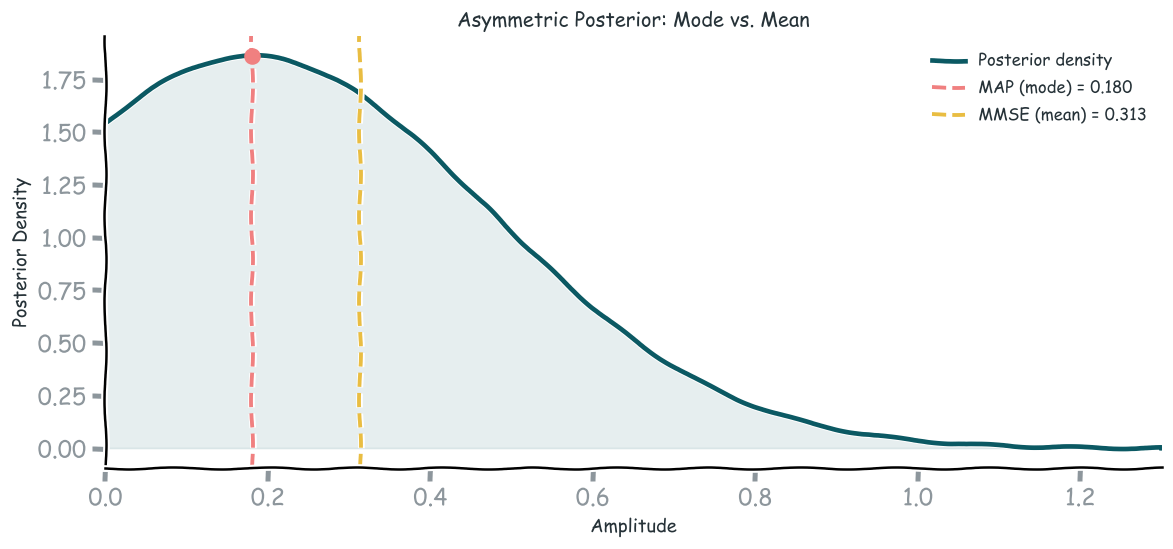

In [35]:
# Posterior Mode vs. Posterior Mean
fig, ax = plt.subplots(figsize=(10, 4.8))

# Posterior distribution
ax.plot(
    a_grid5,
    posterior_density5,
    color=TEAL,
    linewidth=2.8,
    label="Posterior density"
)

ax.fill_between(
    a_grid5,
    posterior_density5,
    color=TEAL,
    alpha=0.10
)

# MAP estimate — posterior mode
ax.axvline(
    a_map5,
    color=RED,
    linestyle="--",
    linewidth=2.3,
    label=rf"MAP (mode) = {a_map5:.3f}"
)

# MMSE estimate — posterior mean
ax.axvline(
    a_mmse5,
    color=YELLOW,
    linestyle="--",
    linewidth=2.3,
    label=rf"MMSE (mean) = {a_mmse5:.3f}"
)

posterior_mode_height = np.interp(
    a_map5,
    a_grid5,
    posterior_density5
)

ax.scatter(
    a_map5,
    posterior_mode_height,
    color=RED,
    s=80,
    zorder=5
)

ax.set_xlabel("Amplitude")
ax.set_ylabel("Posterior Density")

ax.set_title(
    "Asymmetric Posterior: Mode vs. Mean"
)

ax.set_xlim(0, 1.3)

ax.legend(
    frameon=False,
    fontsize=10
)

plt.tight_layout()
plt.show()

The posterior distribution is asymmetric.
It has a relatively steep left side and a longer right tail.

**MAP Estimate**

The MAP estimate corresponds to the highest point of the posterior density:
$$
\hat a_{\mathrm{MAP}} =
\arg\max_a p(a\mid\mathbf y)
$$
In our experiment:
$$
\hat a_{\mathrm{MAP}}
\approx0.180
$$

**MMSE Estimate**

The MMSE estimate corresponds to the posterior mean:
$$
\hat a_{\mathrm{MMSE}} =
\mathbb E[a\mid\mathbf y]
$$

In our experiment:
$$
\hat a_{\mathrm{MMSE}}
\approx0.313
$$

MMSE is larger:  
The posterior distribution has a right tail.
Although the highest posterior density occurs near $0.180$, the posterior also assigns probability to larger amplitudes.
These larger values pull the posterior mean to the right.
Consequently:
$$
\boxed{
\hat a_{\mathrm{MMSE}} >
\hat a_{\mathrm{MAP}}
}
$$
for this particular posterior.


- **The most probable parameter value is not necessarily the posterior mean.**
- MAP selects the maximum of the posterior density.
- MMSE takes the entire posterior distribution into account through its mean.

However, we have not yet demonstrated why the posterior mean is optimal for squared-error loss.


### Why Does the Posterior Mean Minimize Squared Error?

We have observed that the posterior mean and mode can differ. But why should we choose the posterior mean when our objective is to minimize squared error?

#### Posterior Expected Loss

Suppose we choose a candidate estimate $\tilde a$.
The squared-error loss is:
$$
L(a,\tilde a) =
(a-\tilde a)^2
$$
Since the unknown parameter is uncertain under the posterior distribution, we calculate its expected loss:
$$
\boxed{
R(\tilde a\mid\mathbf y) =
\int
(a-\tilde a)^2
p(a\mid\mathbf y)\,da
}
$$
This is called the posterior expected squared-error loss or posterior risk.

Let:
$$
\mu_{\mathrm{post}} =
\mathbb E[a\mid\mathbf y]
$$
and:
$$
\sigma_{\mathrm{post}}^2 =
\operatorname{Var}(a\mid\mathbf y)
$$
Then the posterior expected squared error can be rewritten as:
$$
\boxed{
R(\tilde a\mid\mathbf y) =
\sigma_{\mathrm{post}}^2 +
(\tilde a-\mu_{\mathrm{post}})^2
}
$$
Notice that the posterior variance does not depend on the candidate estimate $\tilde a$.
Therefore, minimizing posterior expected squared error is equivalent to minimizing:
$$
(\tilde a-\mu_{\mathrm{post}})^2
$$
This expression reaches its minimum at:
$$
\tilde a=\mu_{\mathrm{post}}
$$
Consequently:
$$
\boxed{
\hat a_{\mathrm{MMSE}} =
\mathbb E[a\mid\mathbf y]
}
$$

The result does not require a Gaussian posterior. For any posterior distribution with a finite second moment, the posterior mean minimizes expected squared-error loss.

#### Numerical Experiment

We will calculate:
$$
R(\tilde a\mid\mathbf y)
$$
for many candidate estimates $\tilde a$.
Then we will determine which candidate minimizes the expected loss.

> **Q: Which estimate do you expect to minimize posterior expected squared error?**
> - The likelihood maximum (ML).
> - The posterior mode (MAP).
> - The posterior mean (MMSE).


In [36]:
# Posterior Expected Squared Error

candidate_estimates5 = np.linspace(
    0.0,
    1.1,
    450
)

# Calculate posterior expected squared error

squared_error5 = (
    a_grid5[None, :]
    - candidate_estimates5[:, None]
)**2

weighted_squared_error5 = (
    squared_error5
    * posterior_density5[None, :]
)

posterior_risk5 = np.trapezoid(
    weighted_squared_error5,
    x=a_grid5,
    axis=1
)

minimum_risk_index5 = np.argmin(
    posterior_risk5
)

a_minimum_risk5 = candidate_estimates5[
    minimum_risk_index5
]

# Expected loss at ML, MAP, and MMSE
risk_ml5 = np.interp(
    a_ml5,
    candidate_estimates5,
    posterior_risk5
)

risk_map5 = np.interp(
    a_map5,
    candidate_estimates5,
    posterior_risk5
)

risk_mmse5 = np.interp(
    a_mmse5,
    candidate_estimates5,
    posterior_risk5
)

# Display results
print("Posterior Expected Squared Error")
print("-" * 50)

print(f"ML estimate:             {a_ml5:.5f}")
print(f"MAP estimate:            {a_map5:.5f}")
print(f"MMSE estimate:           {a_mmse5:.5f}")

print()
print(
    f"Numerical risk minimizer: "
    f"{a_minimum_risk5:.5f}"
)

print()
print(f"Expected loss at ML:   {risk_ml5:.6f}")
print(f"Expected loss at MAP:  {risk_map5:.6f}")
print(f"Expected loss at MMSE: {risk_mmse5:.6f}")

Posterior Expected Squared Error
--------------------------------------------------
ML estimate:             0.48151
MAP estimate:            0.17993
MMSE estimate:           0.31287

Numerical risk minimizer: 0.31359

Expected loss at ML:   0.073020
Expected loss at MAP:  0.062250
Expected loss at MMSE: 0.044577


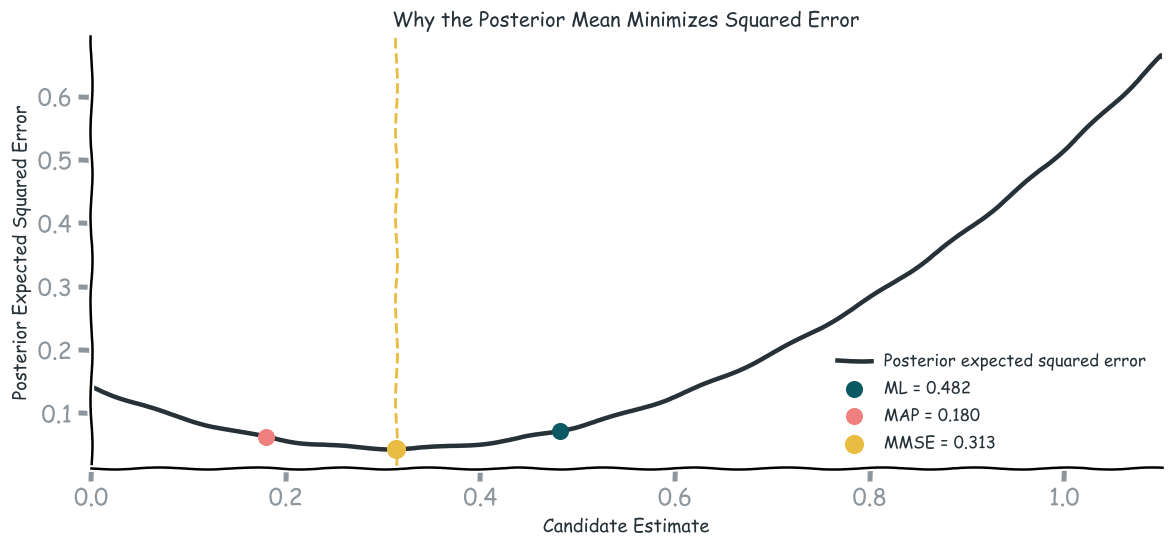

In [37]:
fig, ax = plt.subplots(figsize=(10, 4.8))

# Expected squared-error curve
ax.plot(
    candidate_estimates5,
    posterior_risk5,
    color=DARK,
    linewidth=2.7,
    label="Posterior expected squared error"
)

# ML estimate
ax.scatter(
    a_ml5,
    risk_ml5,
    color=TEAL,
    s=85,
    zorder=5,
    label=rf"ML = {a_ml5:.3f}"
)

# MAP estimate
ax.scatter(
    a_map5,
    risk_map5,
    color=RED,
    s=85,
    zorder=5,
    label=rf"MAP = {a_map5:.3f}"
)

# MMSE estimate
ax.scatter(
    a_mmse5,
    risk_mmse5,
    color=YELLOW,
    s=110,
    zorder=6,
    label=rf"MMSE = {a_mmse5:.3f}"
)

# Mark the MMSE location
ax.axvline(
    a_mmse5,
    color=YELLOW,
    linestyle="--",
    linewidth=1.7
)


ax.set_xlabel("Candidate Estimate")
ax.set_ylabel("Posterior Expected Squared Error")

ax.set_title(
    "Why the Posterior Mean Minimizes Squared Error"
)

ax.set_xlim(
    candidate_estimates5[0],
    candidate_estimates5[-1]
)

ax.legend(
    frameon=False,
    fontsize=10
)

plt.tight_layout()
plt.show()

The horizontal axis represents the candidate estimate $\tilde a$.
The vertical axis represents its posterior expected squared error:
$$
R(\tilde a\mid\mathbf y) =
\mathbb E[
(a-\tilde a)^2
\mid\mathbf y
]
$$
The expected-loss curve has a minimum at the posterior mean.

In our experiment:
$$
\boxed{
\hat a_{\mathrm{MMSE}}
\approx0.313
}
$$
The posterior mode is located at:
$$
\hat a_{\mathrm{MAP}}
\approx0.180
$$
Although MAP selects the most probable parameter value according to the posterior density, it does not minimize posterior expected squared error in this example.

- Why Is MMSE Better Under Squared-Error Loss?

MMSE minimizes the average squared distance between the candidate estimate and all possible parameter values, weighted by their posterior probabilities.
The posterior mean balances these distances in a way that minimizes expected squared error.
The posterior mode instead focuses on the location of maximum posterior density.

**Note:**  
>MMSE is optimal for **posterior expected squared-error loss**. This does not mean that MMSE must be closer to the true parameter in every individual observation. A particular ML or MAP estimate can happen to have a smaller realized error. The optimality of MMSE concerns its expected performance under the assumed posterior distribution and squared-error loss.


**The best point estimate depends on the loss function and the statistical assumptions.**

MAP and MMSE use the same posterior distribution but optimize different criteria.

# Final Comparison: ML, MAP, and MMSE

We have now studied three estimation methods.

* **Maximum Likelihood**

Maximum likelihood selects the parameter that maximizes the likelihood:
$$
\boxed{
\hat a_{\mathrm{ML}} =
\arg\max_a p(\mathbf y\mid a)
}
$$
It relies on the observation model and does not require a prior distribution.

* **Maximum a Posteriori**

MAP selects the parameter that maximizes the posterior density:
$$
\boxed{
\hat a_{\mathrm{MAP}} =
\arg\max_a p(a\mid\mathbf y)
}
$$
It incorporates prior information and selects the posterior mode.

* **Minimum Mean Squared Error**

MMSE selects the posterior mean:
$$
\boxed{
\hat a_{\mathrm{MMSE}} =
\mathbb E[a\mid\mathbf y]
}
$$
It minimizes posterior expected squared-error loss.

***What Should We Compare?***  
All three estimators can be calculated using the same observed signal.
However, they answer different questions.

**ML:** Which parameter best explains the observed data?

**MAP:** Which parameter has the highest posterior density?

**MMSE:** Which point estimate minimizes posterior expected squared error?

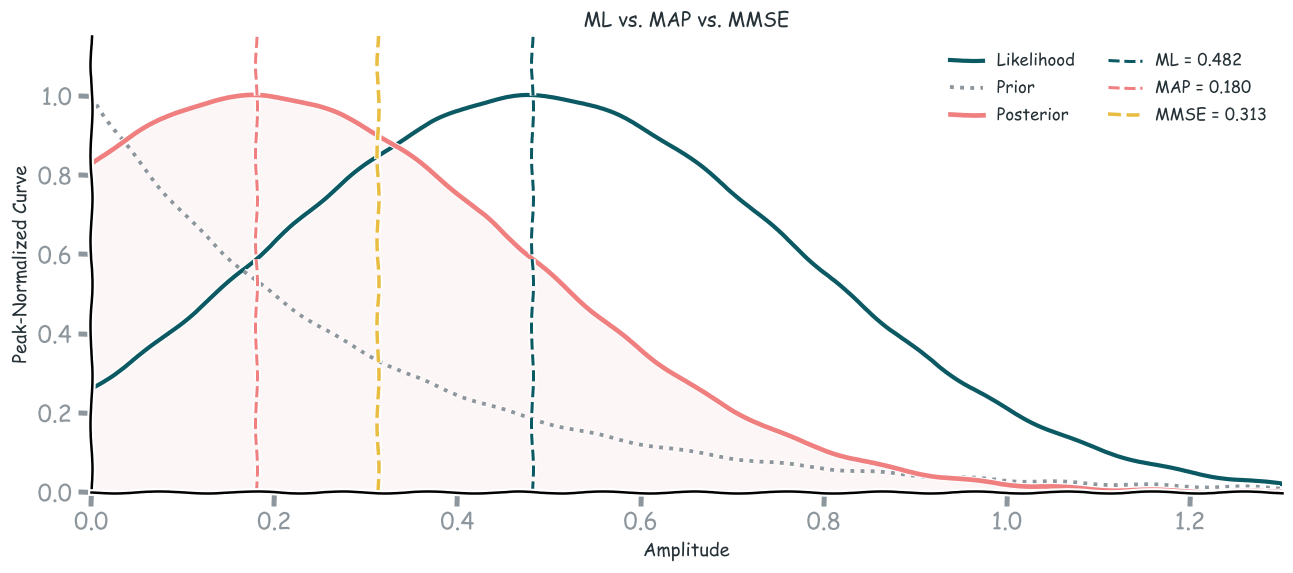

In [38]:
# Likelihood shape
likelihood_shape5 = np.exp(
    -0.5 * (
        (a_grid5 - a_ml_unconstrained5)
        / likelihood_std5
    )**2
)

# Exponential prior
prior_density5 = (
    prior_rate5
    * np.exp(-prior_rate5 * a_grid5)
)

likelihood_scaled5 = (
    likelihood_shape5
    / np.max(likelihood_shape5)
)

prior_scaled5 = (
    prior_density5
    / np.max(prior_density5)
)

posterior_scaled5 = (
    posterior_density5
    / np.max(posterior_density5)
)

# Visualization
fig, ax = plt.subplots(figsize=(11, 5))

# Likelihood
ax.plot(
    a_grid5,
    likelihood_scaled5,
    color=TEAL,
    linewidth=2.5,
    label="Likelihood"
)

# Prior
ax.plot(
    a_grid5,
    prior_scaled5,
    color=GRAY,
    linestyle=":",
    linewidth=2.3,
    label="Prior"
)

# Posterior
ax.plot(
    a_grid5,
    posterior_scaled5,
    color=RED,
    linewidth=2.8,
    label="Posterior"
)

ax.fill_between(
    a_grid5,
    posterior_scaled5,
    color=RED,
    alpha=0.07
)

# ML estimate
ax.axvline(
    a_ml5,
    color=TEAL,
    linestyle="--",
    linewidth=1.8,
    label=rf"ML = {a_ml5:.3f}"
)

# MAP estimate
ax.axvline(
    a_map5,
    color=RED,
    linestyle="--",
    linewidth=1.8,
    label=rf"MAP = {a_map5:.3f}"
)

# MMSE estimate
ax.axvline(
    a_mmse5,
    color=YELLOW,
    linestyle="--",
    linewidth=2.1,
    label=rf"MMSE = {a_mmse5:.3f}"
)

ax.set_xlabel("Amplitude")
ax.set_ylabel("Peak-Normalized Curve")

ax.set_title(
    "ML vs. MAP vs. MMSE"
)

ax.set_xlim(0, 1.3)
ax.set_ylim(0, 1.15)

ax.legend(
    frameon=False,
    fontsize=10,
    ncol=2
)

plt.tight_layout()

fig.savefig(
    "MLSP_Week1_Experiment5_FinalComparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## Optional: Changing the Exponential Prior

Our exponential prior is:
$$
p(a) =
\beta e^{-\beta a},
\qquad a\geq0
$$
where $\beta>0$ is the rate parameter.
The prior mean is:
$$
\mathbb E[a]=\frac{1}{\beta}
$$
Increasing $\beta$ concentrates more prior probability near zero.  
Decreasing $\beta$ produces a more diffuse prior.

### Prediction Question
> **Q:** As the prior becomes increasingly concentrated near zero:
> 1. What happens to the MAP estimate?
> 2. What happens to the MMSE estimate?
> 3. Do they necessarily move together?

Recall that MAP selects the posterior mode, while MMSE selects the posterior mean.
The posterior's asymmetry determines how different these estimates can be.


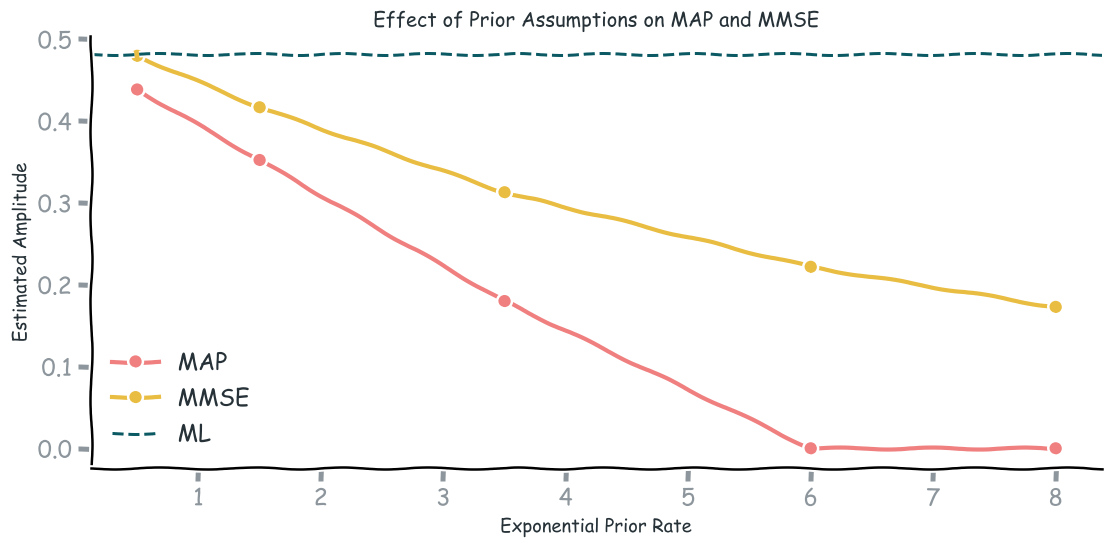

Prior Rate     MAP            MMSE           
---------------------------------------------
0.50           0.4384         0.4796         
1.50           0.3523         0.4167         
3.50           0.1799         0.3129         
6.00           0.0000         0.2218         
8.00           0.0000         0.1728         


In [39]:
prior_rates5 = np.array([
    0.5,
    1.5,
    3.5,
    6.0,
    8.0
])

map_values5 = []
mmse_values5 = []

# Calculate estimates for different prior rates
for beta in prior_rates5:

    m = (
        a_ml_unconstrained5
        - beta * likelihood_var5
    )

    # Standardized lower truncation
    z = -m / likelihood_std5

    # MAP
    map_estimate = max(0.0, m)

    # MMSE
    mmse_estimate = (
        m
        + likelihood_std5
        * norm.pdf(z)
        / norm.sf(z)
    )

    map_values5.append(map_estimate)
    mmse_values5.append(mmse_estimate)

map_values5 = np.array(map_values5)
mmse_values5 = np.array(mmse_values5)

# Visualization
fig, ax = plt.subplots(figsize=(9.5, 4.8))

ax.plot(
    prior_rates5,
    map_values5,
    color=RED,
    marker="o",
    linewidth=2.5,
    label="MAP"
)

ax.plot(
    prior_rates5,
    mmse_values5,
    color=YELLOW,
    marker="o",
    linewidth=2.5,
    label="MMSE"
)

ax.axhline(
    a_ml5,
    color=TEAL,
    linestyle="--",
    linewidth=1.8,
    label="ML"
)

ax.set_xlabel("Exponential Prior Rate")
ax.set_ylabel("Estimated Amplitude")

ax.set_title(
    "Effect of Prior Assumptions on MAP and MMSE"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

# Display results
print(
    f"{'Prior Rate':<15}"
    f"{'MAP':<15}"
    f"{'MMSE':<15}"
)

print("-" * 45)

for beta, map_est, mmse_est in zip(
    prior_rates5,
    map_values5,
    mmse_values5
):

    print(
        f"{beta:<15.2f}"
        f"{map_est:<15.4f}"
        f"{mmse_est:<15.4f}"
    )

## Conclusion

Throughout this session, we learned that obtaining an estimate is only one part of statistical inference.
We must also consider:
- How measurement noise affects estimation uncertainty.
- Whether the unknown parameters are identifiable.
- How prior information influences the estimate.
- Which loss function defines the estimation objective.

These considerations determine not only which estimates we obtain, but also how much confidence we should place in them.

**A reliable estimation procedure must be evaluated in the context of its assumptions, available information, and intended objective.**